# 300_05 — PSBPM-FD con cuatro predictores y tres intervalos contra FAR y RF · Escenario TAR · **barrido en $M$**

Copia del `200_05` sobre los artefactos de la 300 y lo que persiste `300_04`: una fila por predictor en el Bloque A, una banda por construcción en el Bloque B (`111_*` contra el FAR), §9 y §10 sobre la ventana de detalle. Cálculo en `fit/comparacion_barrido.py`, figuras en `graphics/viz_comparacion.py`.

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd
import json

import numpy as np

from model_psbp_fd.fit.convergencia_barrido import cargar_artefactos
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB, cargar_representaciones, serie_origenes,
)
from model_psbp_fd.fit.comparacion_barrido import (
    G_FAR, G_PSG, G_PSB, PISO,
    preparar_diseno, info_generador, ajustar_far, ajustar_rf, cargar_psbp,
    tablas_modelos, verificar_cadena_modelos,
    construir_bandas, tabla_bloque_B, ventana_bloque_B,
    ganadores_por_ventana, resumen_min_max, promedio_vs_M,
    origenes_extremos, contraste_origenes, nombre_psbp, validar_comportamientos_barrido,
    G_PSS, G_PSH, bloqueB_contra_far,
)
from model_psbp_fd.fit.evaluacion_barrido import INTERVALOS as INTERVALOS_TODOS
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.graphics import (
    plot_ventana_movil, ESTILOS_MODELOS, ESTILOS_MODELOS_PREDICTORES, plot_validacion_observado,
    plot_ganador_modelo, plot_metricas_vs_M, plot_bandas_contraste,
)
from model_psbp_fd.fit.comportamientos import cargar_comportamientos, validar_observado
from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Mismos valores que 300_01 §1.1 (la 200 con otro BASENAME).
VARIANTE     = "chungEscG"
BASENAME     = f"escenario_300_{VARIANTE}"
ESCENARIO_ID = 1      # escenario TAR (único)
REPLICA_ID   = 1      # réplica Monte Carlo
M_FPCA_LIST  = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)

# Propias de la comparación. Ventanas, nivel y objetivo se LEEN de eval_config.json
# (artefacto copiado de 200_01): no se redeclaran aquí.
PESOS_TAU = None          # cuadratura trapezoidal por defecto
PREFIJO   = 70            # este notebook escribe 70-83 en cada M y 96-99, 105-107, 111 en el barrido
INTERVALOS  = INTERVALOS_TODOS    # equicolas, simultanea, hdr: una banda del PSBPM-FD por construcción
N_DETALLE   = 10        # orígenes consecutivos de prueba para el análisis predictivo (§9, §10)
T0_DETALLE  = None      # el _05 LEE la ventana del _04 (112_ventana_detalle.json); un entero sólo la verifica
PREDICTORES = PREDICTORES_TODOS   # una fila del PSBPM-FD por predictor puntual (300_04 §3)

# FAR (§3.1): tope del barrido de kn (acota en K, no en L) y criterio de far.cv.
KN_MAX      = 12
CRITERIO_KN = "L2"

# Random Forest (§3.2): hiperparámetros fijos entre escenarios y entre puntos del barrido.
SEED_ML   = 20260830
PARAMS_RF = dict(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                 random_state=SEED_ML, n_jobs=-1)

# Bloque B (§5): FAR con banda gaussiana de residuos de train y PSBPM-FD con su banda
# nativa (cuantiles de su predictiva).
IC_POR_TAU                = True    # sigma_eps(tau) punto a punto (False = ancho constante)
IC_CORRECCION_ESTIMACION  = True    # infla sigma por sqrt(1 + kn/n_train)
IC_PSBP_TAMBIEN_GAUSSIANA = False   # control opcional: no se corre (sólo FAR gaussiano y PSBPM-FD nativo)

# §9: por qué métrica se eligen los orígenes extremos, cuántos, qué dos bandas se
# contrastan (prefijos, en orden) y en qué M (None = todos).
METRICA_SEL_IC     = "rmse_f"     # una de METRICAS_A_COLS
N_EXTREMOS         = 5
BANDA_A_CONTRASTAR = ("FAR", "PSBPM-FD (predictiva")
M_DETALLE          = None

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]
assert METRICA_SEL_IC in METRICAS_A_COLS[:3], "METRICA_SEL_IC: mae_f, rmse_f o linf_medio."

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASENAME, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASENAME, ESCENARIO_ID, REPLICA_ID, project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 96-99, 105-107)")

# Ancho de referencia del documento: None = el de siempre (el del medio, 30; decisión 2026-10-12, para no
# reejecutar el _04). Un entero de VENTANAS_W sobrescribe DIS["W_REF"] sin tocar eval_config.json.
W_REF_DOC = None


EXPERIMENT_BASE : escenario_300_chungEscG_1_r01
barrido en M    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_300_chungEscG_1_r01_barrido_M   (archivos 96-99, 105-107)


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASENAME, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True)
DIS  = cargar_representaciones(EST)
ORIG = serie_origenes(DIS)

T0, N_LAGS, NIVEL = DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W = DIS["VENTANAS_W"]
if W_REF_DOC is not None:
    assert int(W_REF_DOC) in VENTANAS_W, f"W_REF_DOC={W_REF_DOC} no está en {VENTANAS_W}"
    DIS["W_REF"] = int(W_REF_DOC)
W_REF = DIS["W_REF"]
print(f"ancho de referencia de este notebook: w = {W_REF}" + ("  (W_REF_DOC)" if W_REF_DOC is not None else ""))
grilla, X_obj_ev  = DIS["grilla"], ORIG["X_obj_ev"]
t_orig, es_train  = ORIG["t_orig"], ORIG["es_train"]

  M  comp  cadenas  covariables  seed_base
  1     1        3            4  41232
  2     2        3            8  41232
  3     3        3           12  41232
  4     4        3           16  41232
  5     5        3           20  41232
  6     6        3           24  41232
  7     7        3           28  41232
  8     8        3           32  41232
  9     9        3           36  41232
 10    10        3           40  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=1  FPCA M=1 K=10  var. explicada=42.3063%  ·  curvas (1000, 75)
M=2  FPCA M=2 K=10  var. explicada=69.2705%  ·  curvas (1000, 75)
M=3  FPCA M=3 K=10  var. explicada=84.2086%  ·  curvas (1000, 75)
M=4  FPCA M=4 K=10  var. explicada=91.4081%  ·  curvas (1000, 75)
M=5  FPCA M=5 K=10  var. explicada=95.2358%  ·  curvas (1000, 75)
M=6  FPCA M=6 K=10  var. explicada=97.4576%  ·  curvas (1000, 75)
M=7  FPCA M=7 K=10  var. explicada=98.6746%  ·  curvas (1000, 75)
M=8  FPCA M=8 K=10 

M=10  FPCA M=10 K=10  var. explicada=100.0000%  ·  curvas (1000, 75)

OK 10 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1000 T0=700 n_lags=4   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


In [4]:
# Ventana de detalle: la que eligió el _04 (§3.2), leída de 112_ventana_detalle.json; no se recalcula.
VD = json.loads((PATH_BARRIDO / "112_ventana_detalle.json").read_text(encoding="utf-8"))
assert VD["n"] == N_DETALLE, f"el _04 usó N_DETALLE={VD['n']}"
assert T0_DETALLE is None or int(T0_DETALLE) == VD["t0"], f"el _04 usó T0_DETALLE={VD['t0']}"
T0_DET   = int(VD["t0"])
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any()
MASK_DET = np.isin(np.arange(len(t_orig)), IDX_DET)
T_DET    = t_orig[IDX_DET]
print(f"Ventana de detalle del _04: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {VD['criterio']}: {VD['valor']}")

Ventana de detalle del _04: t = 807..816   ·   cambios de régimen verdadero en los scores activos, suma sobre la ventana: 14.0


## 2. Validaciones para aplicar los modelos

In [5]:
preparar_diseno(EST, DIS, ORIG)
info_generador(EST[next(iter(EST))], N_LAGS)

origenes evaluados: 996  (train 696 · test 300)
MISE del TRUNCAMIENTO FPCA (piso comun a todos los modelos de cada M):
  M= 1   train 0.639716   test 0.616813
  M= 2   train 0.340970   test 0.352150
  M= 3   train 0.175048   test 0.201787
  M= 4   train 0.095452   test 0.102009
  M= 5   train 0.052846   test 0.056520
  M= 6   train 0.028272   test 0.031054
  M= 7   train 0.014730   test 0.014402
  M= 8   train 0.006660   test 0.006728
  M= 9   train 0.002304   test 0.002189
  M=10   train 0.000000   test 0.000000
R^2 L2 del oraculo de Bayes (4 rezagos) = 0.5130   ·   mejor lineal en los mismos rezagos = 0.1272


## 3. Los competidores

### 3.1 FAR(p), p = N_LAGS, sobre los coeficientes de la base en la métrica $L^2$

Blanqueo con la Cholesky de la Gram (identidad con base ortonormal, verificado con `assert`); `pesos="conteo"`.

In [6]:
FAR = ajustar_far(EST, DIS, ORIG, KN_MAX, CRITERIO_KN)

base: K = 10   ·   cond(W) = 1.00   ·   ||x||_L2 == ||theta_w||_2 (error relativo 1.00e-10)
far.cv: hold-out de las ultimas 140 curvas de train · kn_max = 10
  kn         L1         L2       Linf      L1max      L2max    Linfmax
   1     0.1961     0.3100     0.7953     0.4427     0.6398     2.9672  <-
   2     0.1959     0.3109     0.7980     0.4483     0.6453     2.9896
   3     0.1939     0.3101     0.8001     0.4483     0.6452     2.9914
   4     0.1931     0.3111     0.8017     0.4487     0.6448     2.9591
   5     0.1922     0.3105     0.8020     0.4511     0.6527     2.9983
   6     0.1934     0.3121     0.8042     0.4494     0.6531     2.9945
   7     0.1955     0.3152     0.8124     0.4723     0.6607     2.9023
   8     0.1954     0.3158     0.8145     0.4725     0.6640     2.8086
   9     0.1947     0.3145     0.8123     0.4689     0.6615     2.8082
  10     0.1966     0.3173     0.8201     0.4778     0.6700     2.8278
kn elegido por L2: 1   (L1 -> 5, Linf -> 1)   amplitud re

### 3.2 Random Forest

Un bosque por componente con las mismas covariables que el PSBPM-FD (los rezagos propios); el orden $1..N_{lags}$ se elige por ventanas de train ganadas en `mae_f`.

In [7]:
ajustar_rf(EST, DIS, ORIG, PARAMS_RF, PESOS_TAU)

M=1: RF orden=4   (orden elegido por ventanas de train: 4 (76.3% de 667) de [1, 2, 3, 4])   ·   1 modelos univariantes (rezagos propios)


M=2: RF orden=4   (orden elegido por ventanas de train: 4 (92.1% de 667) de [1, 2, 3, 4])   ·   2 modelos univariantes (rezagos propios)


M=3: RF orden=4   (orden elegido por ventanas de train: 4 (96.3% de 667) de [1, 2, 3, 4])   ·   3 modelos univariantes (rezagos propios)


M=4: RF orden=4   (orden elegido por ventanas de train: 4 (99.7% de 667) de [1, 2, 3, 4])   ·   4 modelos univariantes (rezagos propios)


M=5: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   5 modelos univariantes (rezagos propios)


M=6: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   6 modelos univariantes (rezagos propios)


M=7: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   7 modelos univariantes (rezagos propios)


M=8: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   8 modelos univariantes (rezagos propios)


M=9: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   9 modelos univariantes (rezagos propios)


M=10: RF orden=4   (orden elegido por ventanas de train: 4 (100.0% de 667) de [1, 2, 3, 4])   ·   10 modelos univariantes (rezagos propios)


### 3.3 PSBPM-FD

Predictores e intervalos se leen de `banda_funcional_psbp.npz`; una fila `PSBPM-FD (<predictor>)` por predictor y las bandas con la esperanza.

In [8]:
M_OK = cargar_psbp(EST, DIS, ORIG, predictores=PREDICTORES, intervalos=INTERVALOS)

OK PSBPM-FD leido del _04 en M = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


## 4. Bloque A: error puntual, todos los modelos

MAE, RMSE y error máximo sobre la misma ventana móvil, para FAR, RF y cada predictor del PSBPM-FD.

[M=9] Jensen: 3/6566 ventanas con rmse_f > linf_medio (exceso relativo max 4.27%)
OK cadena L1 <= L2 <= Linf verificada en 10 puntos (w=30)


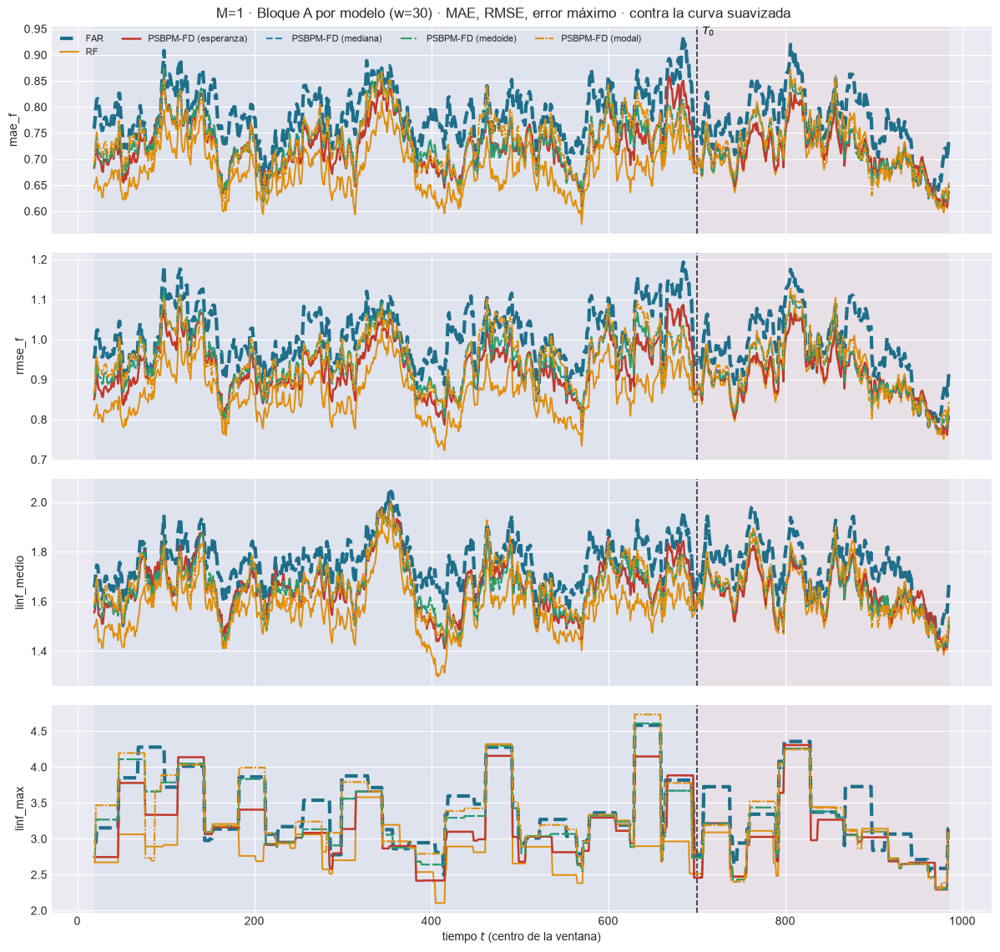

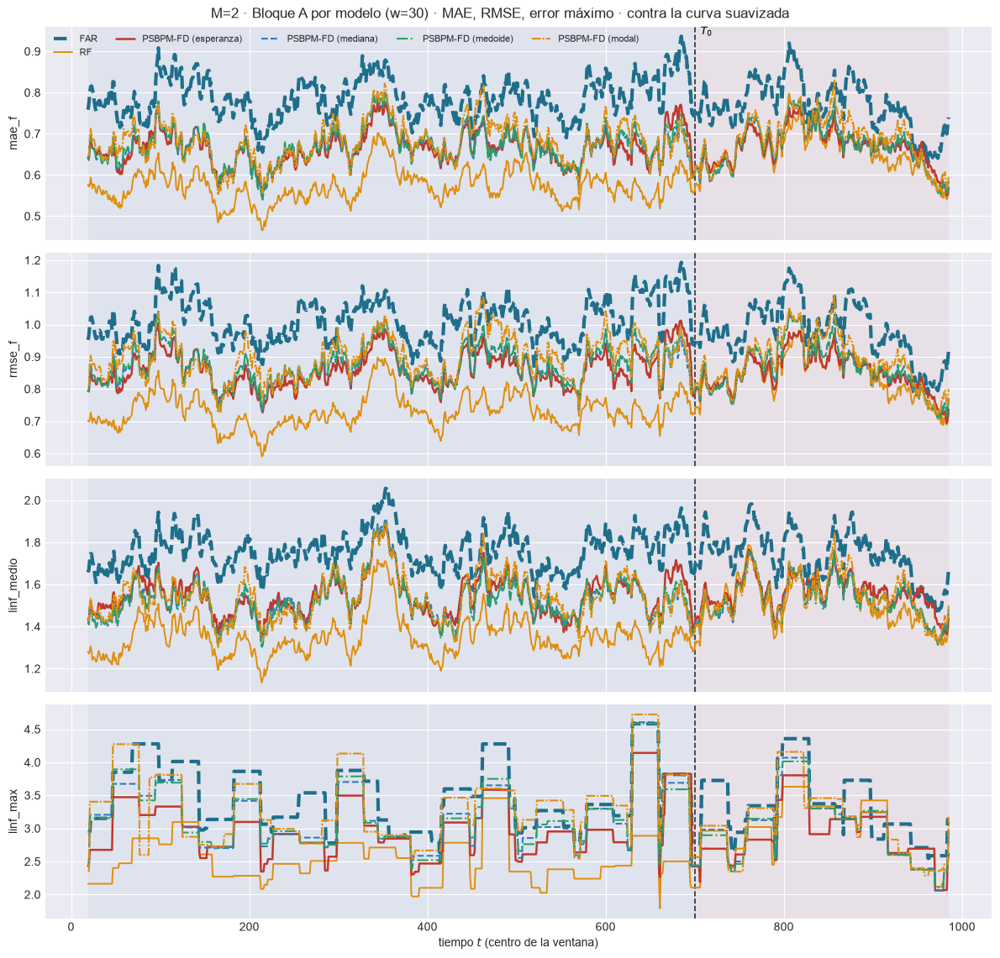

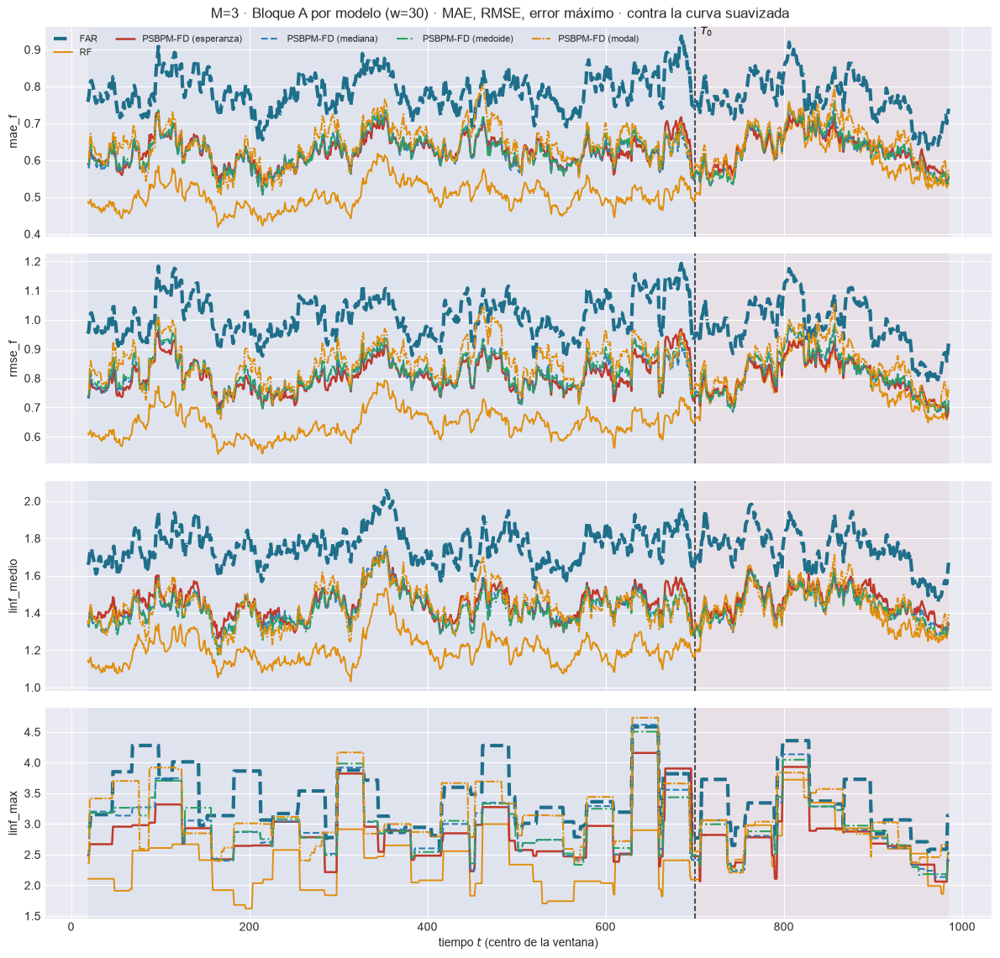

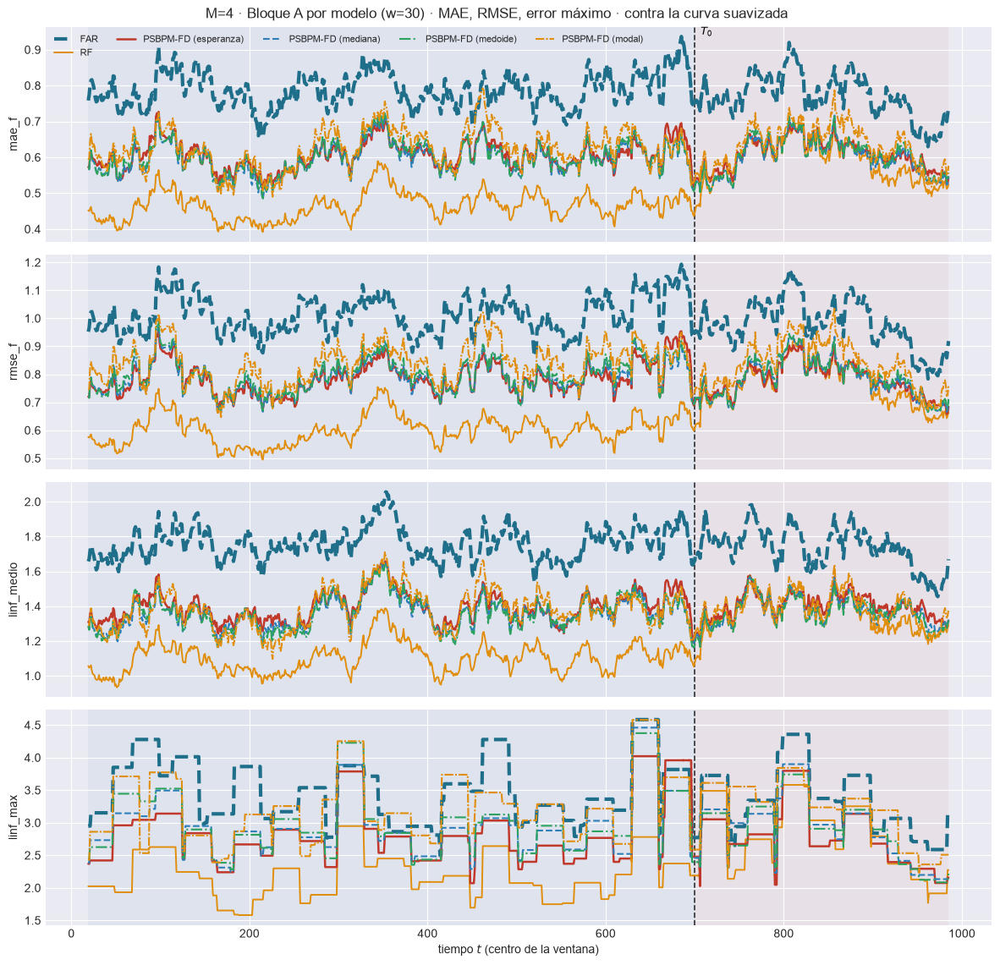

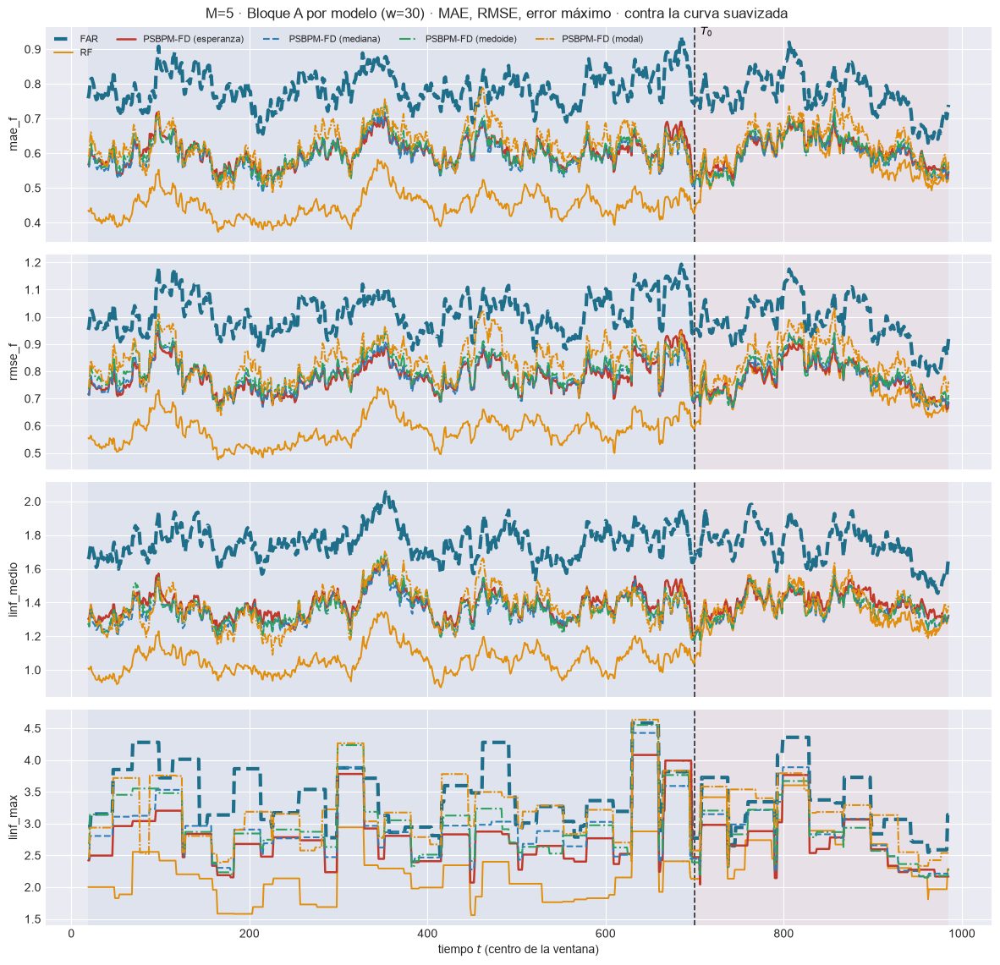

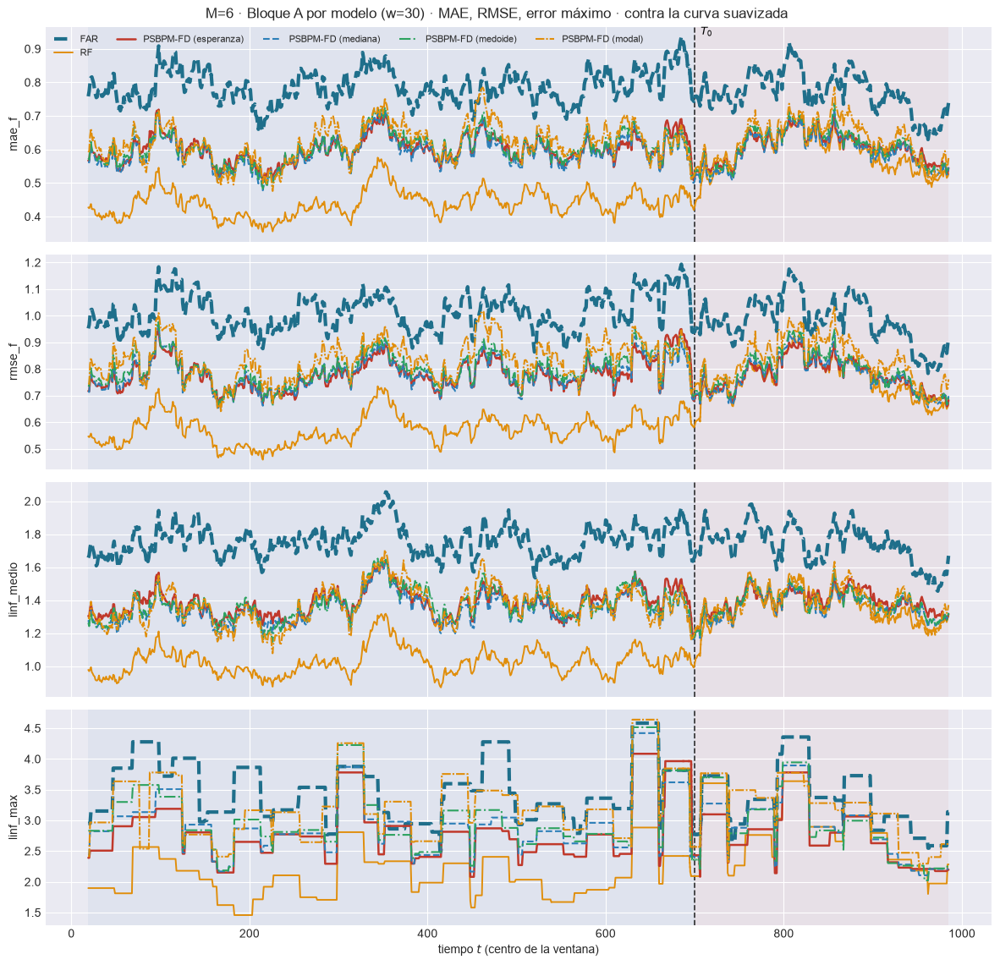

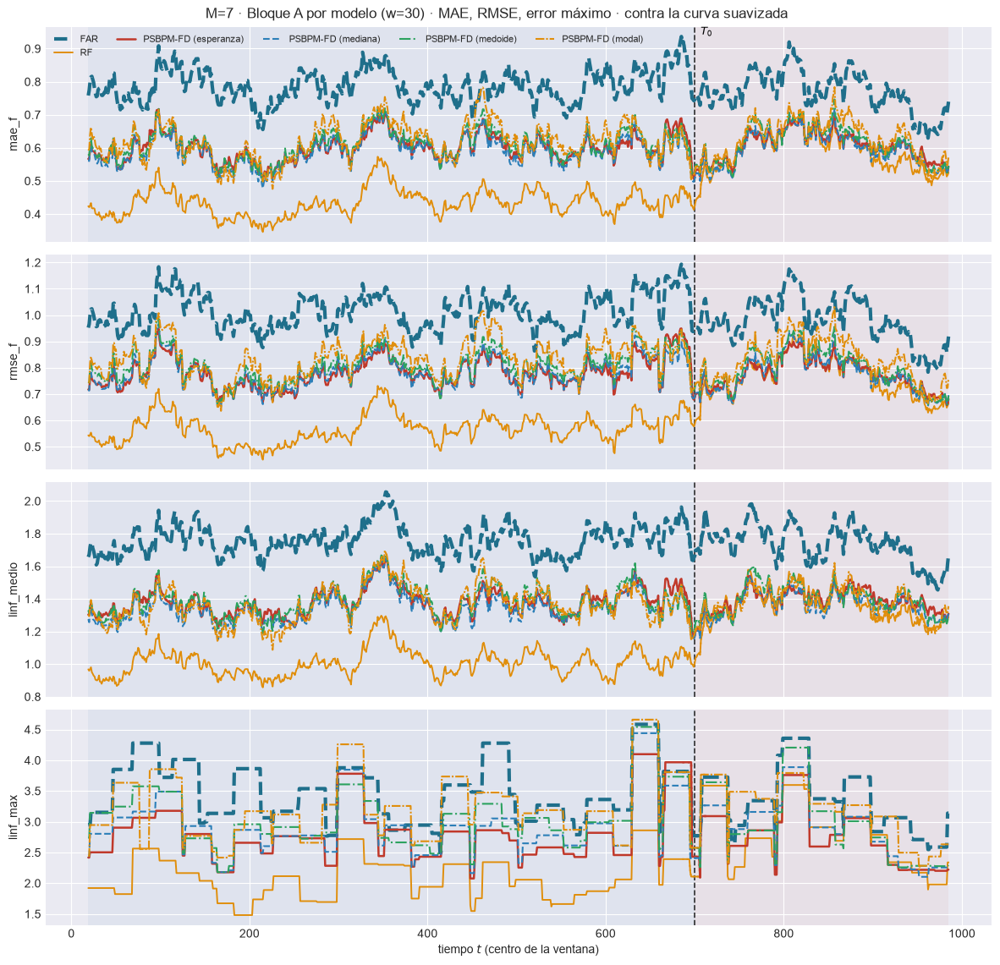

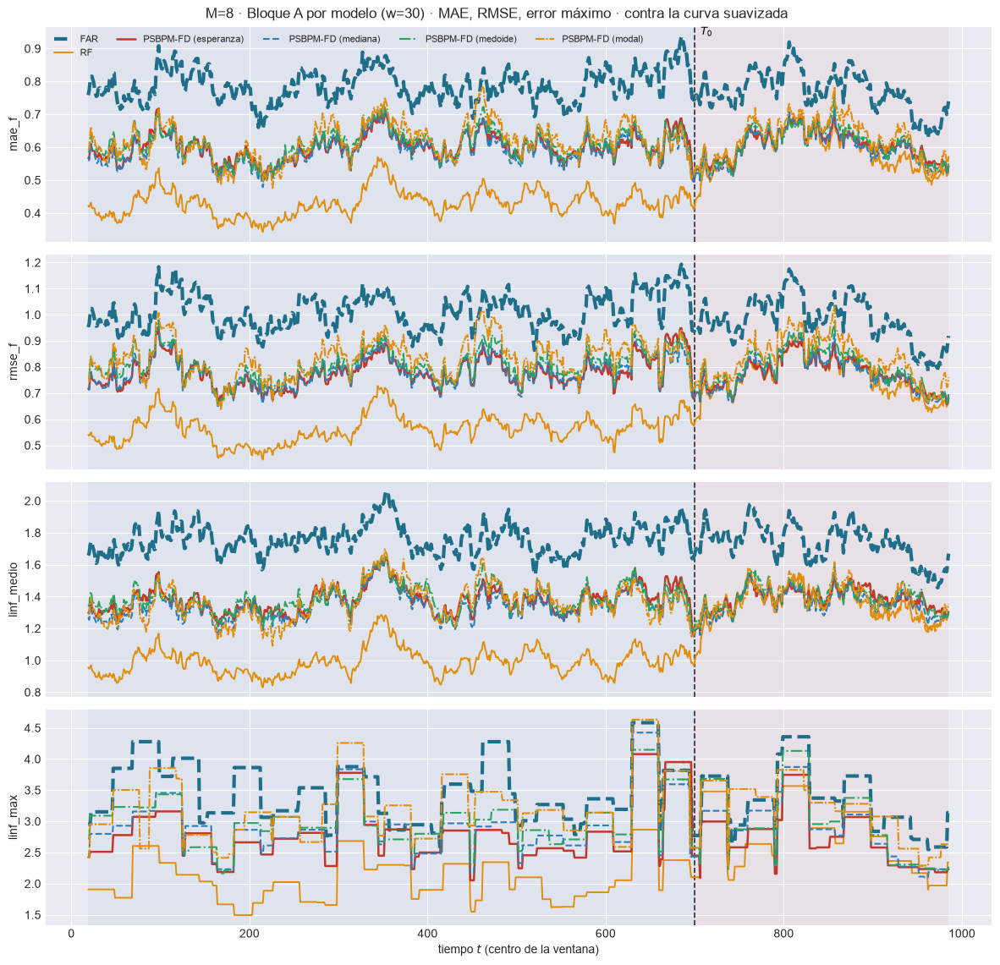

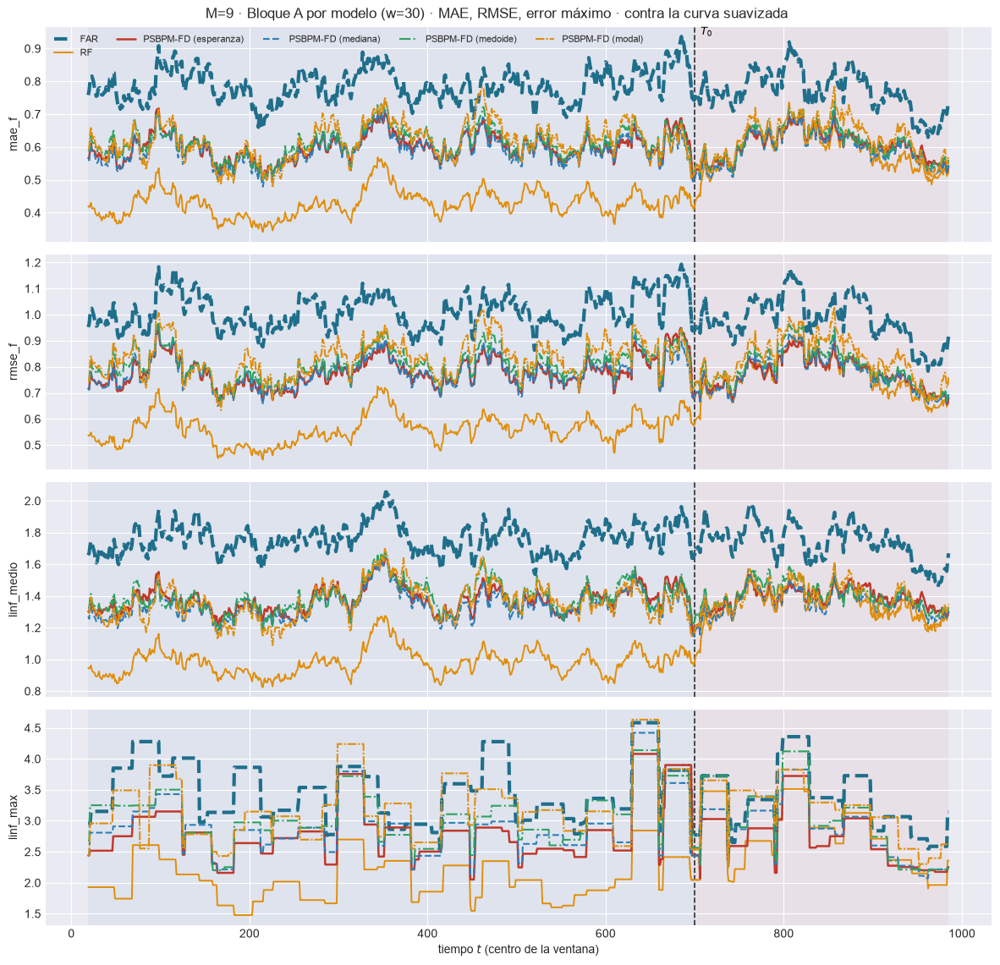

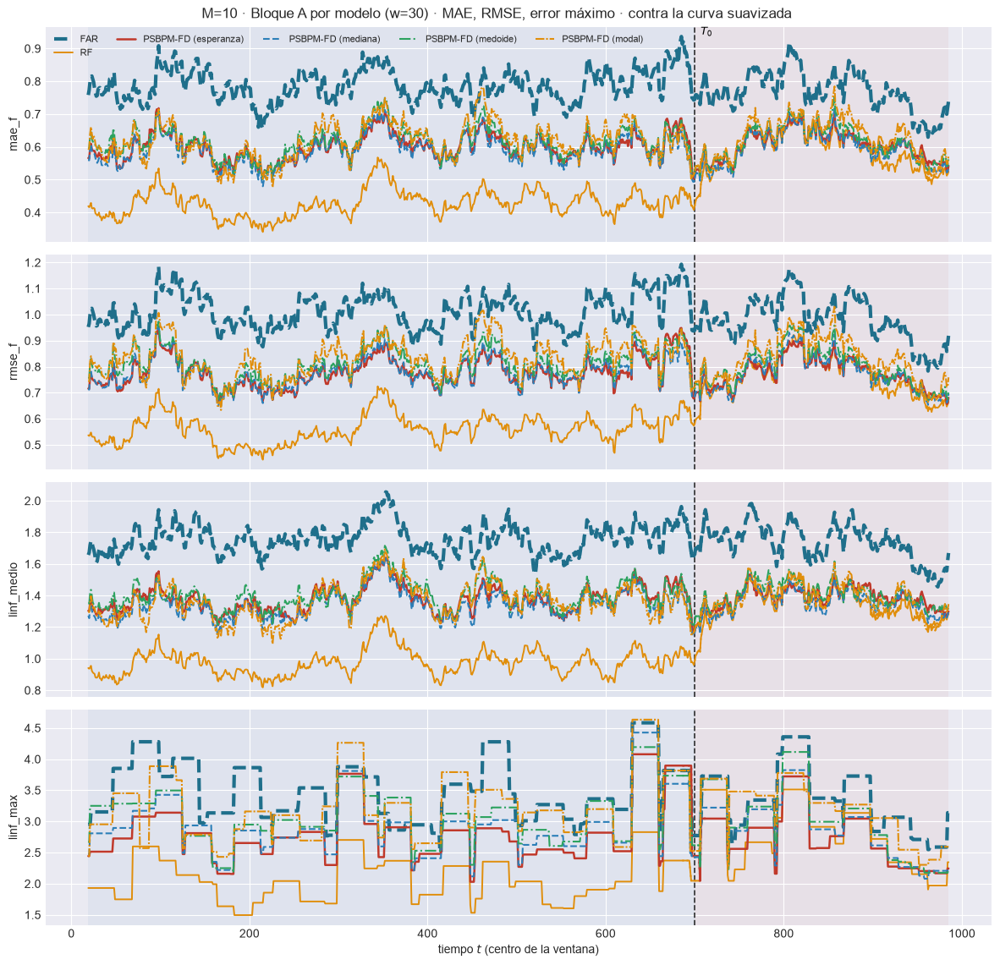

In [9]:
for M in M_OK:
    tablas_modelos(EST[M], DIS, ORIG, PESOS_TAU, PREFIJO)
verificar_cadena_modelos(EST, W_REF)

# Una figura por M; el piso de truncamiento va en las tablas pero no en la figura.
for M in M_OK:
    e = EST[M]
    tw = e["tablas_w"][W_REF]
    tf = tw[tw["modelo"] != PISO].copy()
    tf.attrs["w"] = W_REF
    plot_ventana_movil(
        tf, T0, METRICAS_A_COLS, columna_grupo="modelo", estilos=ESTILOS_MODELOS_PREDICTORES,
        title=f"M={M} · Bloque A por modelo (w={W_REF}) · MAE, RMSE, error máximo · contra la curva suavizada",
        save_path=str(e["paths"]["out_report"] / f"{PREFIJO + 8}_ventana_bloqueA_modelos_w{W_REF}.png"),
        verbose=False)
    plt.show()

## 5. Bloque B: intervalos, sólo FAR y PSBPM-FD (tres construcciones)

El RF no tiene mecanismo de intervalo propio. Del PSBPM-FD, equi-colas, simultánea y HDR con la esperanza, y el contraste misma predictiva, distinta construcción.

In [10]:
for M in M_OK:
    e = EST[M]
    construir_bandas(e, DIS, ORIG, IC_POR_TAU, IC_CORRECCION_ESTIMACION, IC_PSBP_TAMBIEN_GAUSSIANA,
                     intervalos_psbp=INTERVALOS)
    B_df = tabla_bloque_B(e, DIS, ORIG)
    display(B_df.loc["test"].style
            .format({"winkler": "{:.4f}", "picp": "{:.4f}", "ee_picp": "{:.4f}", "ace": "{:+.4f}",
                     "mpiw": "{:.4f}", "picp_simultaneo": "{:.4f}"})
            .background_gradient(subset=["winkler"], cmap="RdYlGn_r")
            .set_caption(f"M={M} · Bloque B, bloque de PRUEBA · PRIMARIA: winkler · nivel nominal {NIVEL:.0%}"))

M=1  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = -1.2321   región de máxima densidad - equi-colas = +0.1125
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.2176   región de máxima densidad - equi-colas = -0.3311


M=2  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +0.7885   región de máxima densidad - equi-colas = -0.3917
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +3.0263   región de máxima densidad - equi-colas = -0.2289


M=3  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +3.3018   región de máxima densidad - equi-colas = -0.2860
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +4.4157   región de máxima densidad - equi-colas = -0.1687


M=4  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)
        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.7859   región de máxima densidad - equi-colas = -0.2189
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +3.0684   región de máxima densidad - equi-colas = -0.1400


M=5  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.6743   región de máxima densidad - equi-colas = -0.1611
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.8018   región de máxima densidad - equi-colas = -0.1318


M=6  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.4361   región de máxima densidad - equi-colas = -0.1327
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.4910   región de máxima densidad - equi-colas = -0.1231


M=7  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.5248   región de máxima densidad - equi-colas = -0.1238
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.5424   región de máxima densidad - equi-colas = -0.1193


M=8  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.4583   región de máxima densidad - equi-colas = -0.1216
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.4674   región de máxima densidad - equi-colas = -0.1166


M=9  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.4652   región de máxima densidad - equi-colas = -0.1163
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.4703   región de máxima densidad - equi-colas = -0.1136


M=10  kn=1  correccion=1.0007  sigma_eps(tau) del FAR: min=0.8806 max=1.0917 (razon 1.24)


        curva_suavizada      misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.4631   región de máxima densidad - equi-colas = -0.1113
        representacion_fpca  misma PREDICTIVA, distinta CONSTRUCCION: banda simultánea - equi-colas = +2.4631   región de máxima densidad - equi-colas = -0.1113


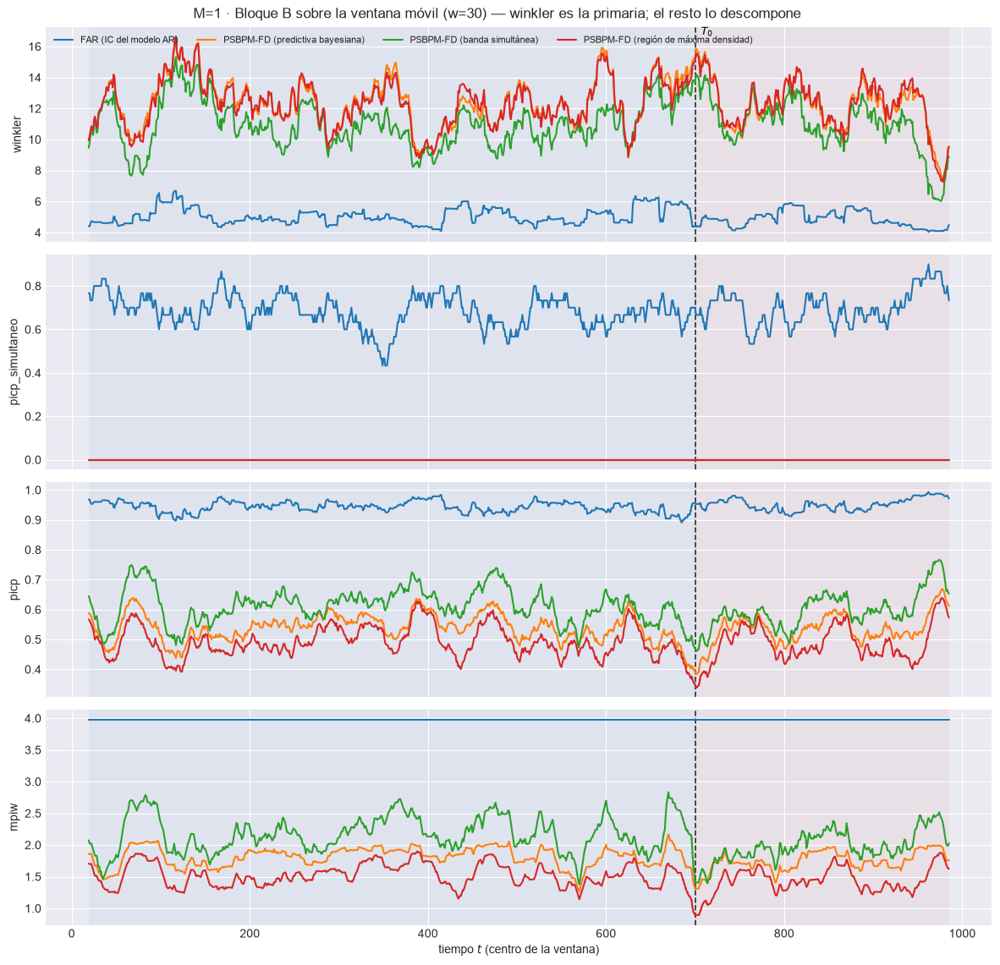

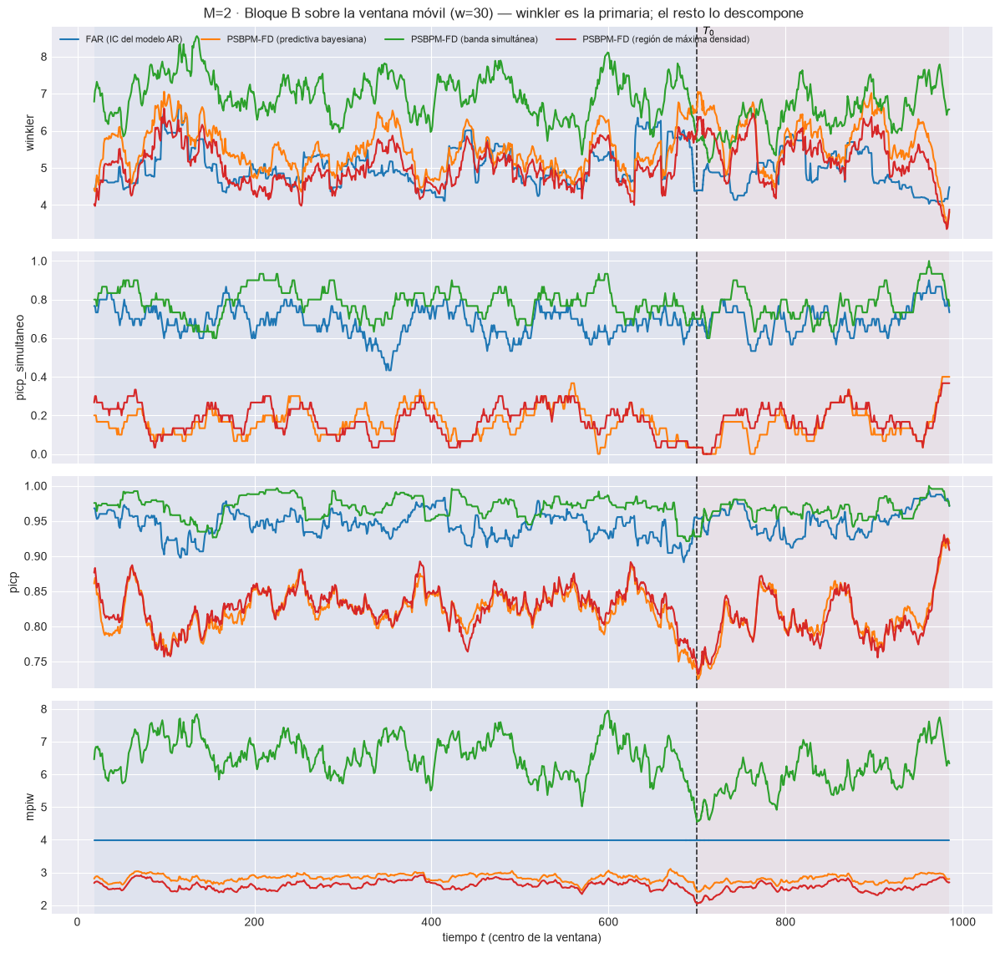

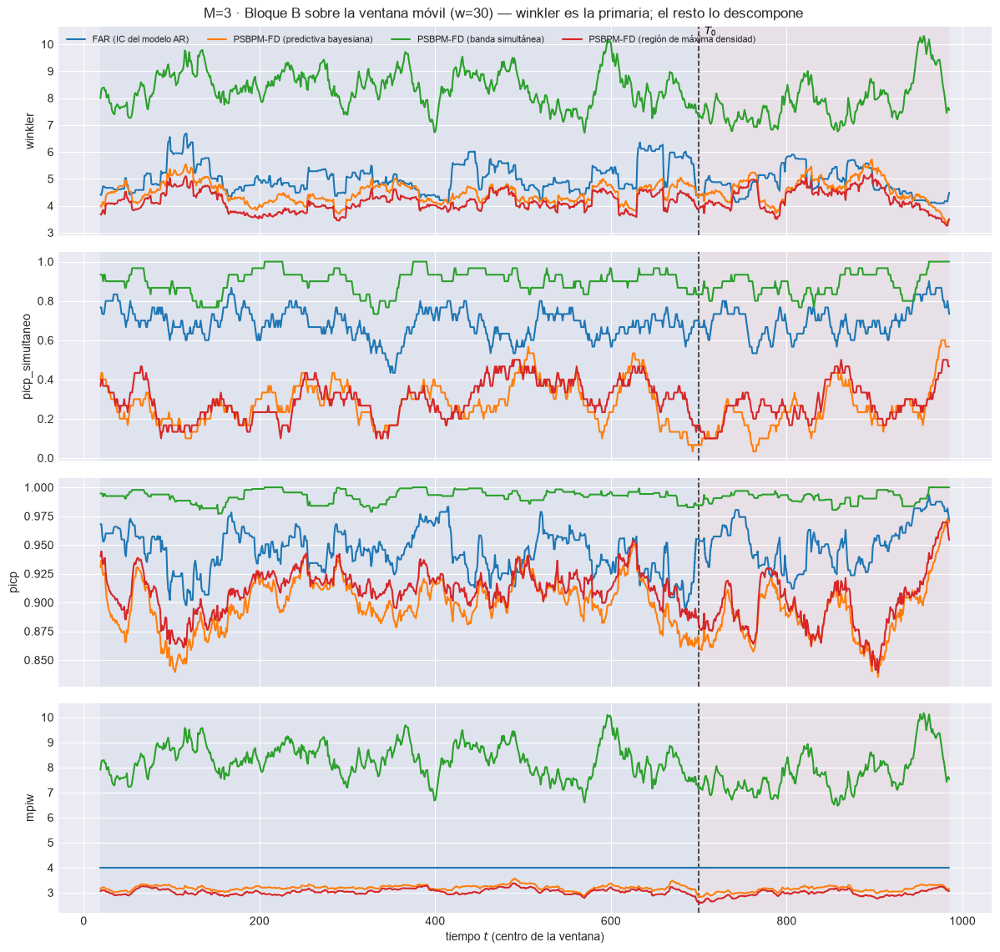

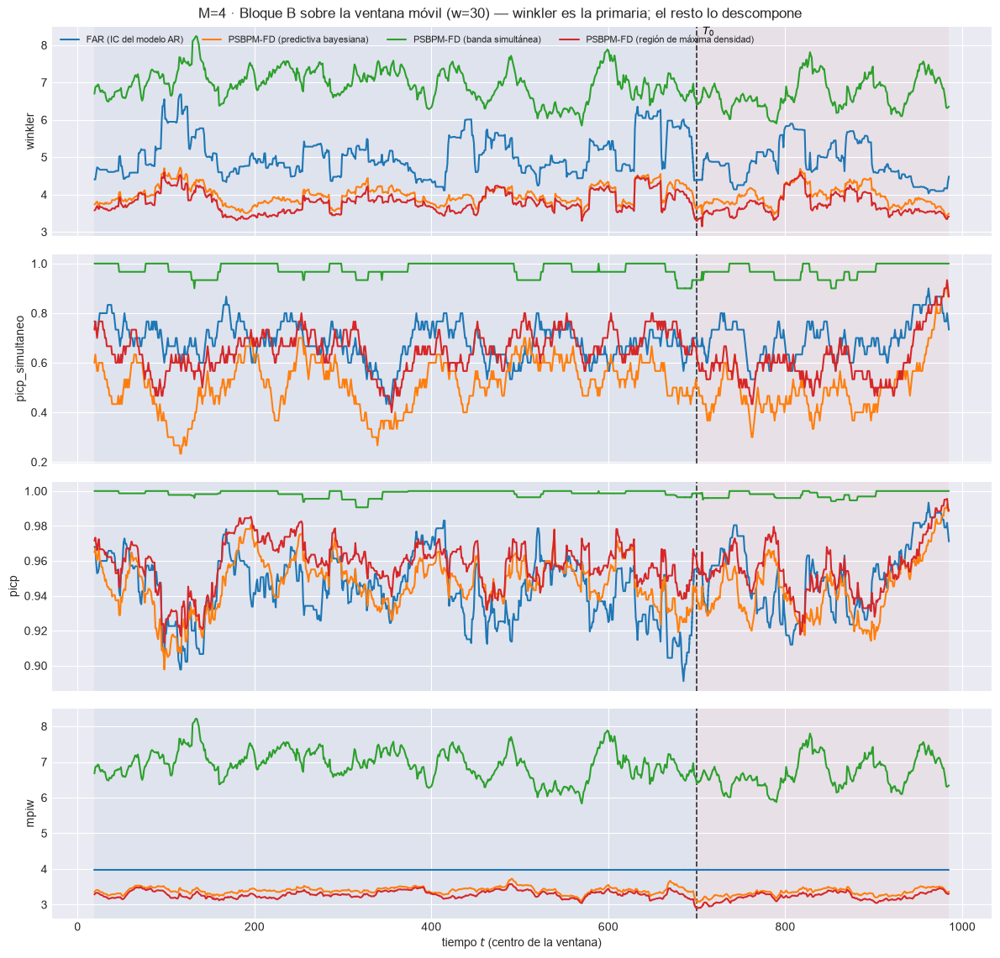

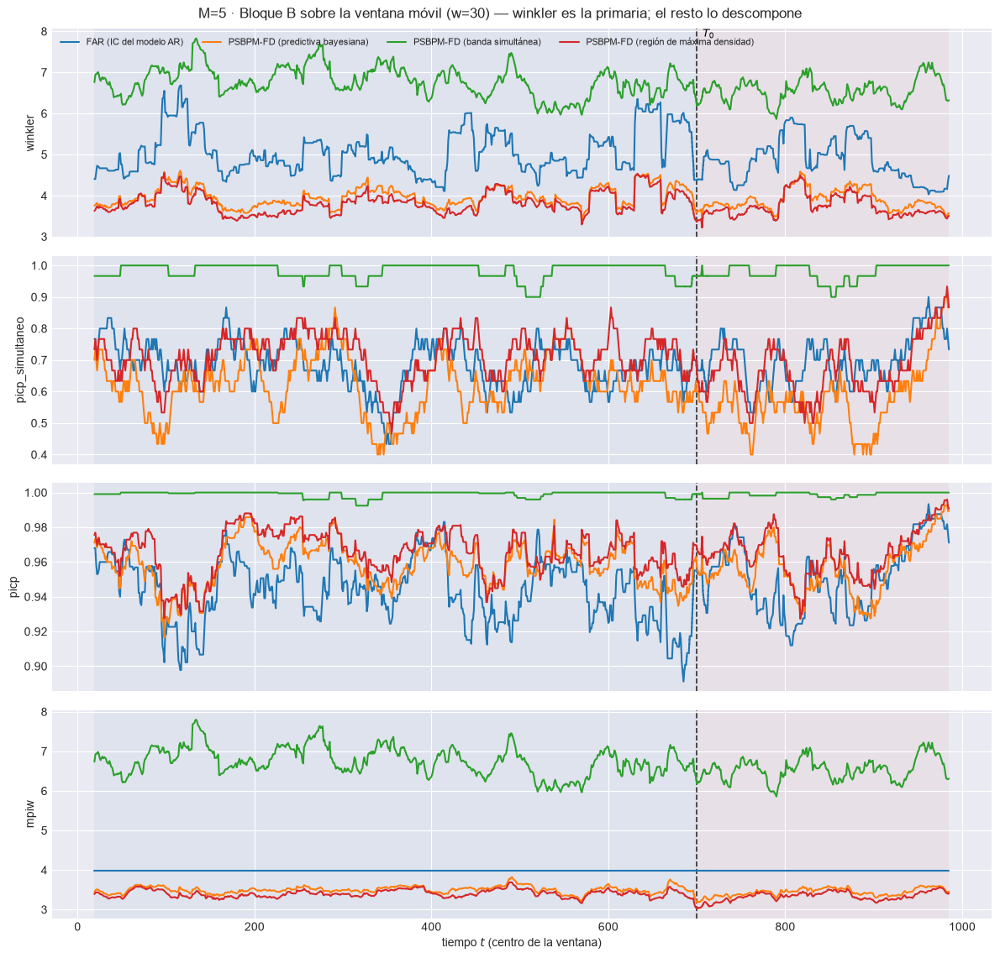

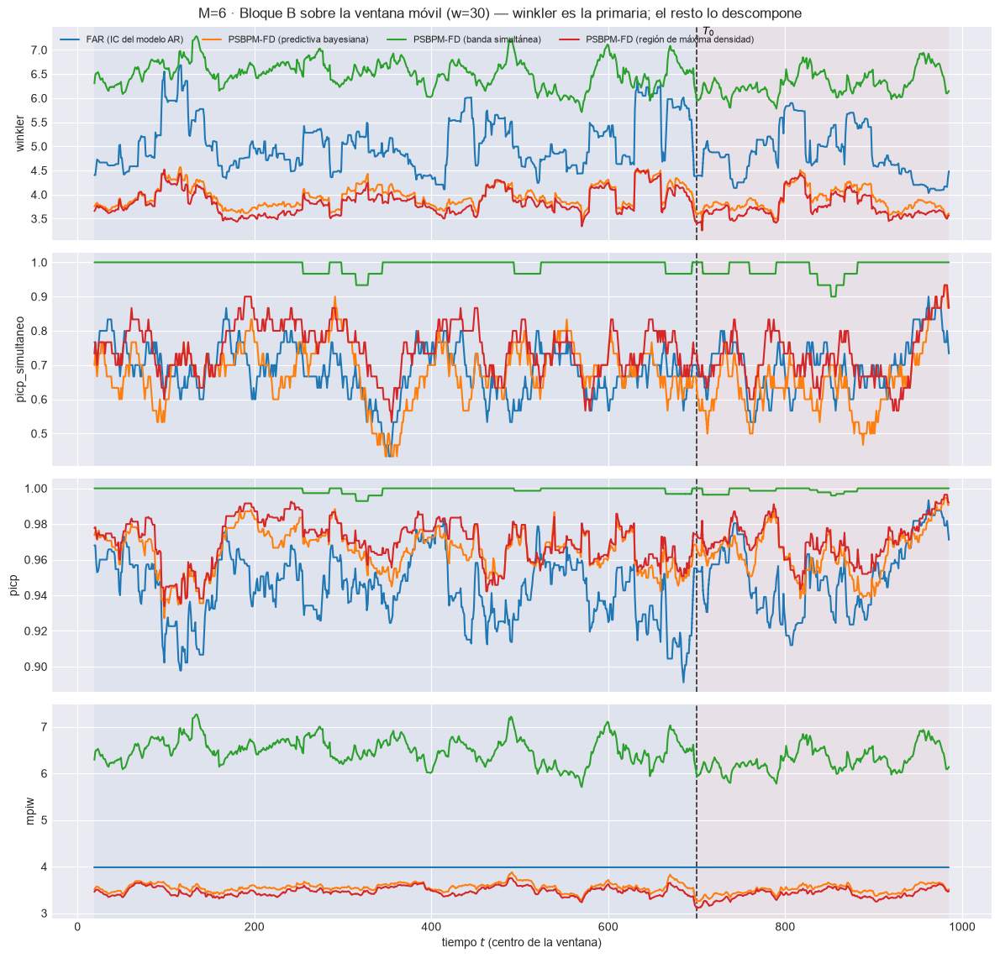

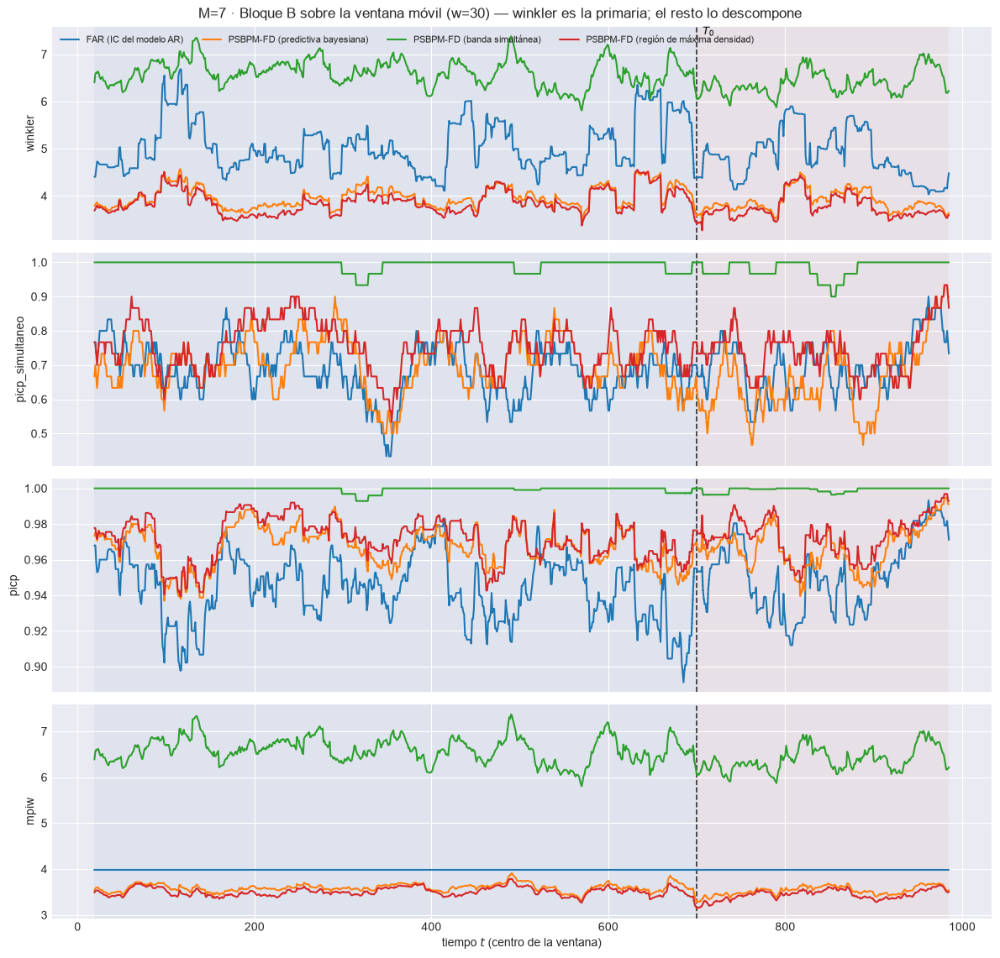

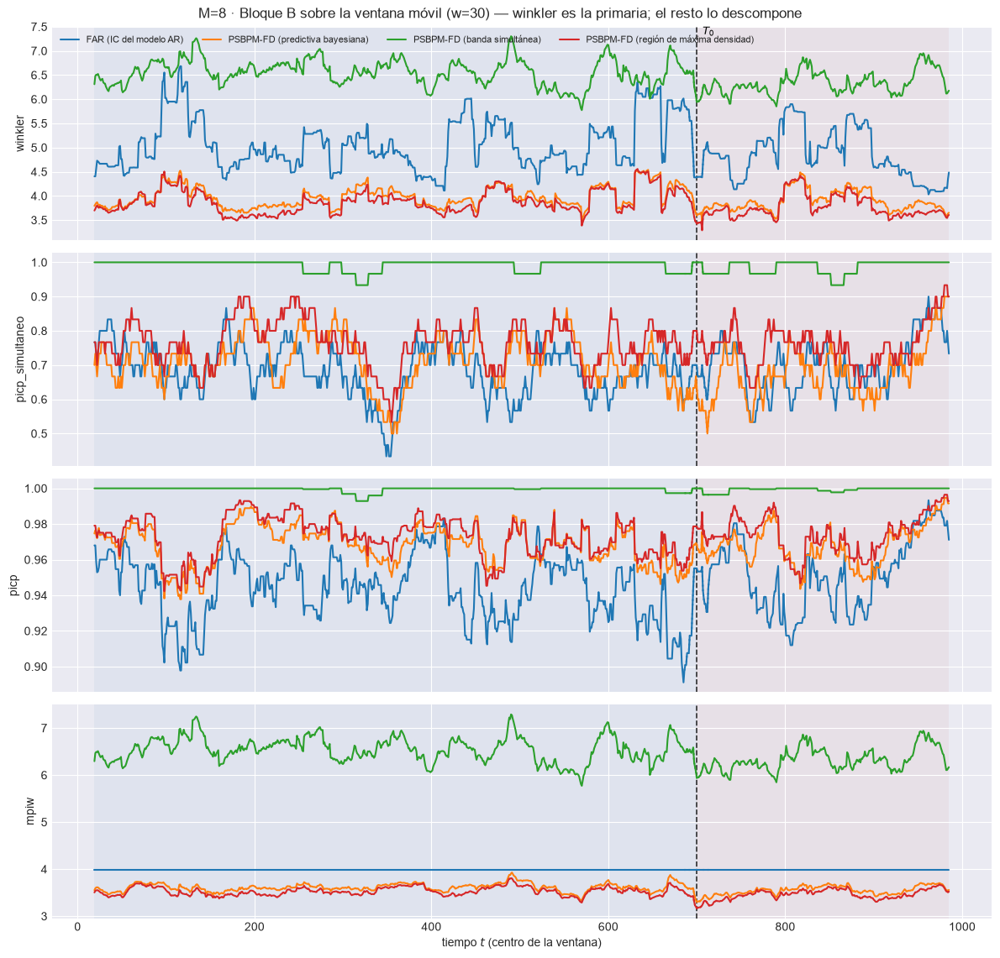

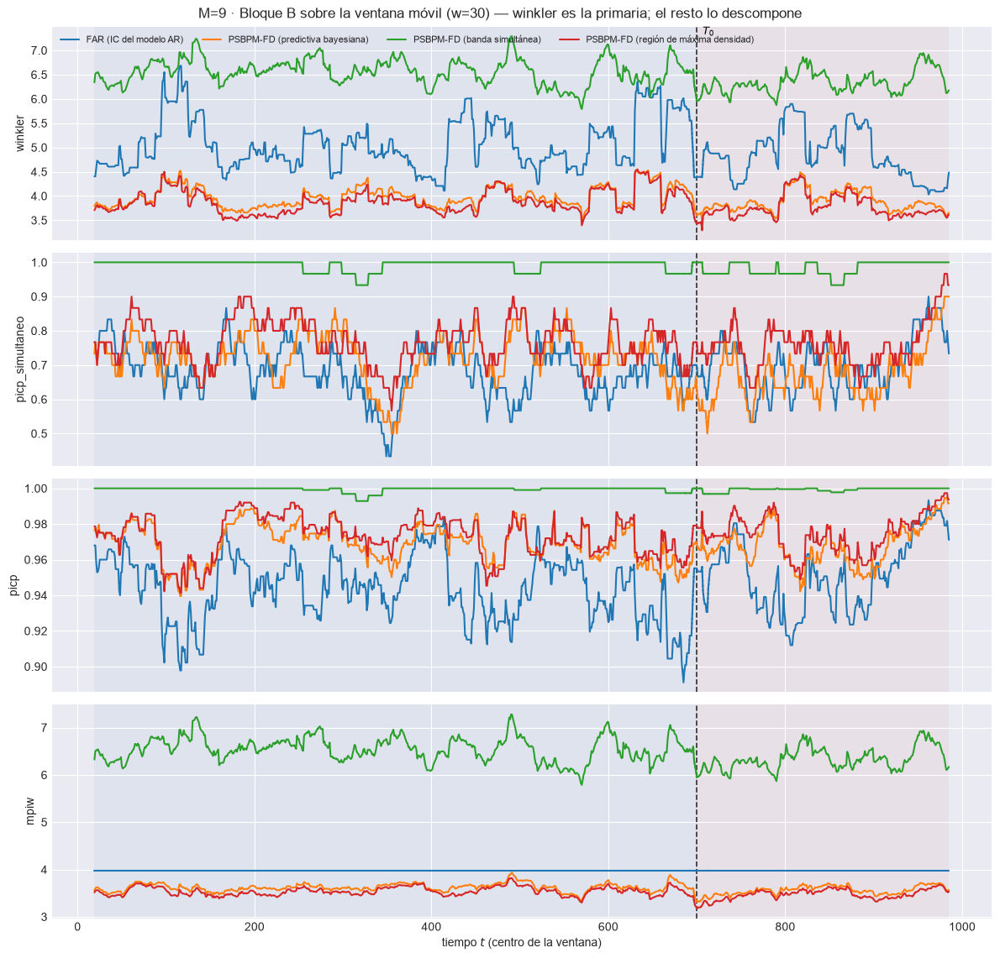

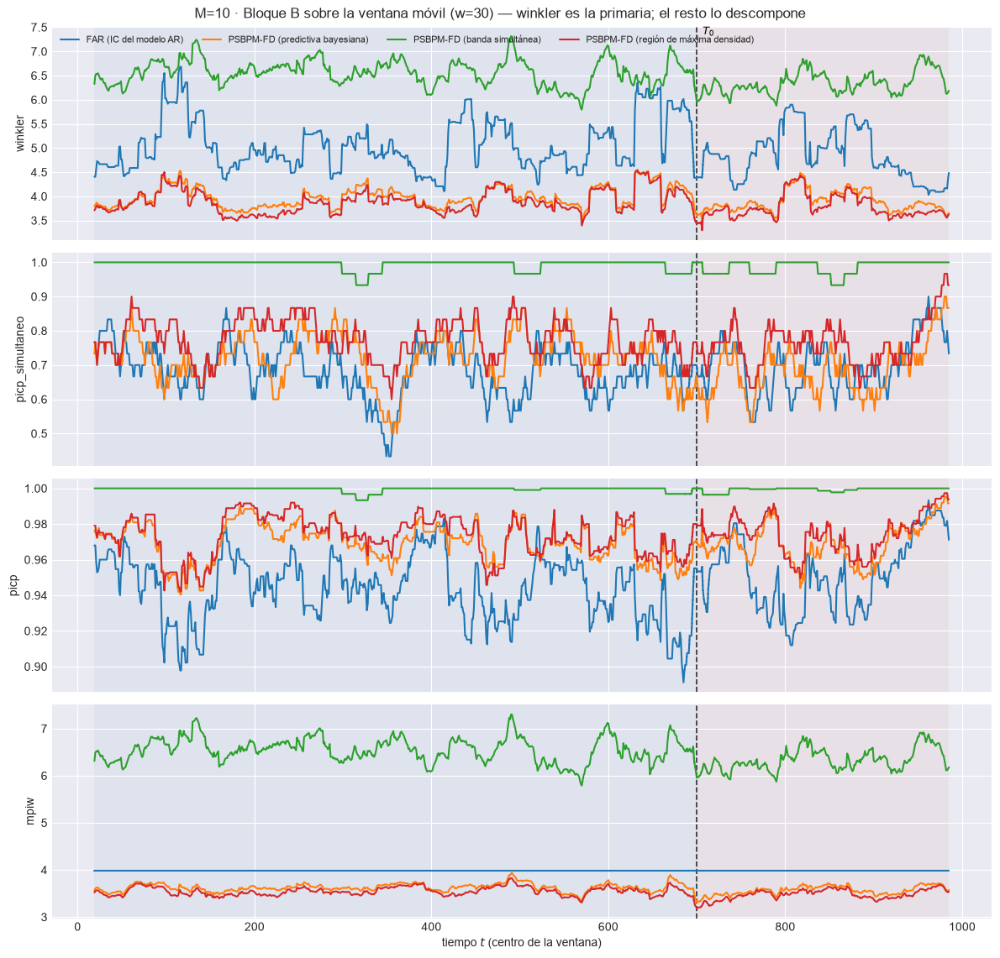

In [11]:
# Winkler sobre la ventana móvil y su descomposición: dice CUÁNDO falla la banda, no sólo cuánto.
for M in M_OK:
    e = EST[M]
    vb = ventana_bloque_B(e, DIS, ORIG, PESOS_TAU, PREFIJO)
    plot_ventana_movil(
        vb, T0, ["winkler", "picp_simultaneo", "picp", "mpiw"], columna_grupo="banda",
        title=f"M={M} · Bloque B sobre la ventana móvil (w={W_REF}) — winkler es la primaria; el resto lo descompone",
        save_path=str(e["paths"]["out_report"] / f"81_ventana_bloqueB_w{W_REF}.png"), verbose=False)
    plt.show()

## 6. Bloque A: quién gana cada ventana, y por cuánto

% de ventanas ganadas y razón contra el mejor y contra el FAR, sin las ventanas que cruzan $T_0$.

M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,2.6%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (esperanza),17.0%,14.4%,6.3%,6.6%,4.4%,4.4%,4.8%,3.0%,4.4%,4.4%
PSBPM-FD (mediana),5.9%,14.0%,8.9%,20.3%,15.5%,30.3%,28.8%,24.7%,31.7%,31.4%
PSBPM-FD (medoide),3.0%,3.0%,11.8%,4.1%,13.3%,0.0%,2.6%,9.2%,0.0%,0.0%
PSBPM-FD (modal),14.4%,1.5%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
RF,57.2%,67.2%,73.1%,69.0%,66.8%,65.3%,63.8%,63.1%,63.8%,64.2%


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,1.093,1.175,1.259,1.312,1.314,1.311,1.313,1.314,1.313,1.313
PSBPM-FD (esperanza),1.014,1.027,1.038,1.043,1.042,1.038,1.039,1.040,1.039,1.038
PSBPM-FD (mediana),1.022,1.030,1.034,1.030,1.027,1.024,1.024,1.025,1.024,1.024
PSBPM-FD (medoide),1.022,1.030,1.036,1.041,1.041,1.045,1.052,1.048,1.051,1.053
PSBPM-FD (modal),1.029,1.053,1.065,1.081,1.079,1.075,1.075,1.075,1.074,1.074
RF,1.009,1.003,1.007,1.006,1.006,1.007,1.007,1.008,1.007,1.007


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,2.2%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (esperanza),25.8%,22.1%,14.8%,15.9%,20.3%,21.0%,21.8%,21.4%,21.4%,21.4%
PSBPM-FD (mediana),2.6%,13.3%,7.7%,10.0%,10.0%,17.3%,18.5%,18.8%,18.5%,18.8%
PSBPM-FD (medoide),2.6%,3.3%,12.5%,8.9%,4.4%,0.4%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (modal),16.2%,1.1%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
RF,50.6%,60.1%,64.9%,65.3%,65.3%,61.3%,59.8%,59.8%,60.1%,59.8%


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,1.093,1.171,1.246,1.287,1.289,1.289,1.290,1.291,1.291,1.291
PSBPM-FD (esperanza),1.011,1.020,1.027,1.028,1.026,1.025,1.024,1.024,1.024,1.024
PSBPM-FD (mediana),1.025,1.033,1.036,1.033,1.029,1.026,1.026,1.025,1.025,1.025
PSBPM-FD (medoide),1.025,1.033,1.039,1.041,1.043,1.045,1.052,1.054,1.053,1.056
PSBPM-FD (modal),1.033,1.061,1.077,1.100,1.098,1.096,1.096,1.096,1.096,1.096
RF,1.010,1.006,1.007,1.005,1.005,1.006,1.006,1.006,1.007,1.007


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,0.4%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (esperanza),21.8%,3.7%,2.6%,1.8%,7.0%,8.1%,8.1%,7.4%,7.4%,7.4%
PSBPM-FD (mediana),9.6%,10.0%,12.5%,4.8%,15.9%,19.9%,21.4%,25.8%,24.4%,29.5%
PSBPM-FD (medoide),0.7%,20.3%,14.4%,34.3%,10.3%,5.2%,5.5%,1.1%,4.1%,0.4%
PSBPM-FD (modal),17.0%,21.0%,17.7%,10.7%,15.5%,18.5%,18.5%,18.1%,18.8%,18.8%
RF,50.6%,45.0%,52.8%,48.3%,51.3%,48.3%,46.5%,47.6%,45.4%,43.9%


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,1.080,1.155,1.233,1.293,1.290,1.293,1.296,1.297,1.299,1.299
PSBPM-FD (esperanza),1.017,1.041,1.045,1.051,1.046,1.044,1.044,1.043,1.044,1.043
PSBPM-FD (mediana),1.017,1.023,1.028,1.028,1.023,1.022,1.022,1.022,1.022,1.021
PSBPM-FD (medoide),1.018,1.021,1.026,1.025,1.028,1.033,1.047,1.048,1.053,1.056
PSBPM-FD (modal),1.021,1.029,1.033,1.039,1.035,1.035,1.035,1.033,1.033,1.034
RF,1.010,1.011,1.012,1.013,1.011,1.014,1.015,1.015,1.016,1.016


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,5.5%,7.4%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (esperanza),36.2%,39.9%,43.5%,37.6%,28.0%,36.2%,36.5%,49.4%,45.8%,51.3%
PSBPM-FD (mediana),7.0%,5.2%,0.7%,0.4%,1.5%,5.5%,3.7%,3.7%,4.1%,4.1%
PSBPM-FD (medoide),1.1%,5.5%,7.0%,8.9%,19.9%,17.3%,19.2%,0.4%,5.9%,0.4%
PSBPM-FD (modal),21.0%,16.6%,14.4%,2.6%,2.2%,2.2%,2.2%,2.2%,2.2%,2.2%
RF,29.2%,25.5%,34.3%,50.6%,48.3%,38.7%,38.4%,44.3%,42.1%,42.1%


M,1,2,3,4,5,6,7,8,9,10
modelo,,,,,,,,,,
FAR,1.111,1.189,1.232,1.253,1.266,1.258,1.261,1.267,1.274,1.271
PSBPM-FD (esperanza),1.018,1.039,1.029,1.046,1.048,1.040,1.042,1.044,1.046,1.044
PSBPM-FD (mediana),1.040,1.074,1.064,1.096,1.096,1.089,1.092,1.094,1.094,1.093
PSBPM-FD (medoide),1.040,1.070,1.070,1.089,1.084,1.094,1.106,1.127,1.144,1.140
PSBPM-FD (modal),1.047,1.098,1.112,1.210,1.216,1.210,1.214,1.222,1.224,1.220
RF,1.026,1.060,1.053,1.036,1.035,1.040,1.040,1.039,1.039,1.039


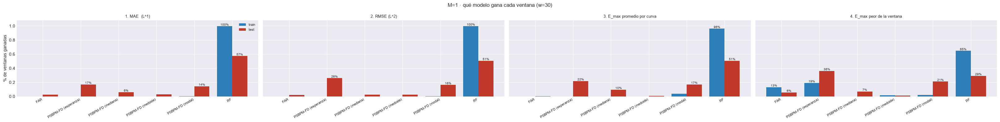

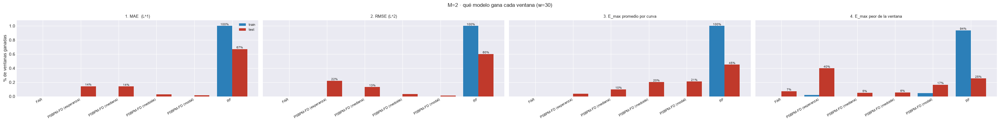

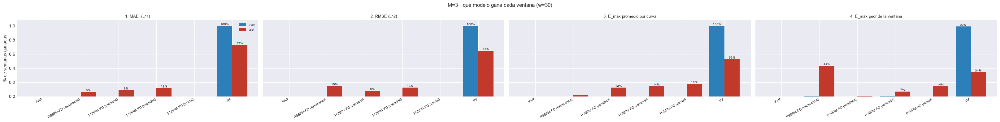

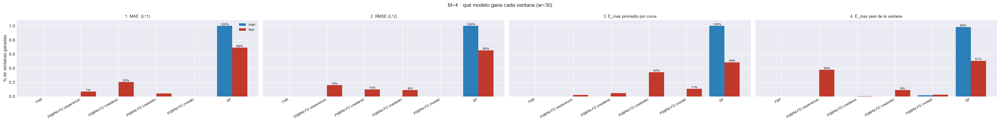

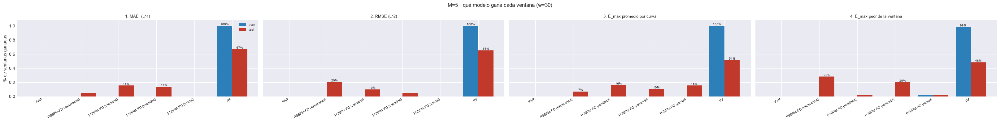

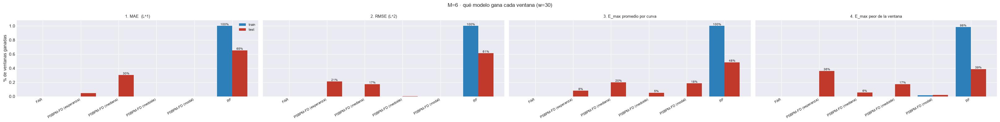

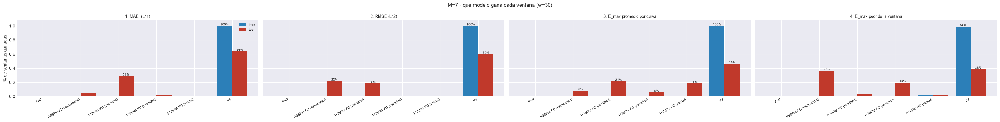

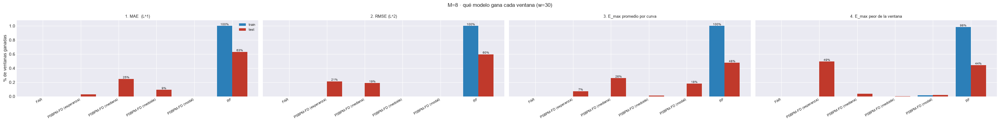

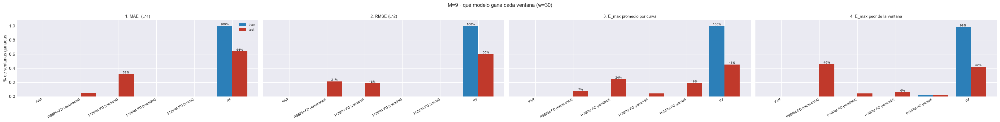

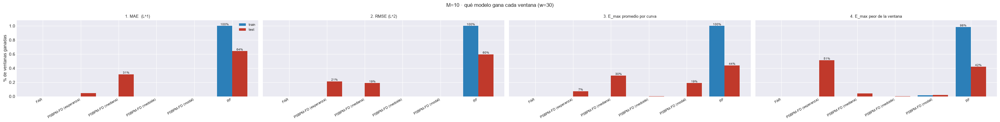

In [12]:
gana_A, rel_A = ganadores_por_ventana(EST, "ventana_df", "modelo", METRICAS_A, NIVEL, excluir=(PISO,))
gana_A.to_csv(PATH_BARRIDO / "96_ganador_ventana_bloqueA.csv", index=False)
rel_A.to_csv(PATH_BARRIDO / "96_razones_bloqueA.csv", index=False)

for etiqueta, _col in METRICAS_A:
    for tabla, v, fmt, cmap, cap in (
            (gana_A, "pct_ventanas_ganadas", "{:.1%}", "RdYlGn",
             f"{etiqueta} · % de ventanas de PRUEBA ganadas (w={W_REF}, sin cruzar T0)"),
            (rel_A, "razon_vs_mejor", "{:.3f}", "RdYlGn_r",
             f"{etiqueta} · razón contra el MEJOR de cada ventana (test) · 1.000 = gana siempre")):
        piv = (tabla[(tabla.metrica == etiqueta) & (tabla.bloque == "test")]
               .pivot(index="modelo", columns="M", values=v))
        display(piv.style.format(fmt, na_rep="-").background_gradient(cmap=cmap, axis=None).set_caption(cap))

for M in M_OK:
    plot_ganador_modelo(gana_A, M, METRICAS_A, W_REF,
                        EST[M]["paths"]["out_report"] / f"{PREFIJO + 8}_ganador_ventana_bloqueA.png")
    plt.show()

In [13]:
# Cada predictor del PSBPM-FD contra FAR y RF por separado (106_ganador_psbp_por_predictor.csv).
partes = []
for p in PREDICTORES:
    otros = [nombre_psbp(q) for q in PREDICTORES if q != p]
    g, _ = ganadores_por_ventana(EST, "ventana_df", "modelo", METRICAS_A, NIVEL, excluir=(PISO, *otros))
    partes.append(g[g.modelo == nombre_psbp(p)].assign(predictor=p))
gana_P = pd.concat(partes, ignore_index=True)
gana_P.to_csv(PATH_BARRIDO / "106_ganador_psbp_por_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(gana_P[(gana_P.metrica == etiqueta) & (gana_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST que gana el PSBPM-FD con cada predictor, contra FAR y RF"))

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,27.3%,19.9%,20.3%,18.5%,19.6%,21.4%,22.9%,22.5%,21.4%,21.8%
mediana,23.2%,21.8%,22.5%,27.7%,29.2%,33.9%,34.3%,34.7%,35.4%,35.1%
medoide,23.2%,20.7%,21.0%,21.4%,23.2%,12.9%,12.5%,21.0%,11.1%,8.9%
modal,21.4%,8.1%,10.0%,1.8%,1.8%,3.0%,3.0%,3.7%,3.3%,3.7%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,38.4%,36.2%,29.2%,26.2%,29.5%,31.0%,31.7%,31.4%,31.4%,31.4%
mediana,24.0%,25.5%,23.6%,22.1%,20.7%,26.2%,28.4%,29.2%,28.8%,29.2%
medoide,24.0%,24.7%,21.0%,17.3%,15.1%,8.1%,2.6%,4.4%,5.9%,3.3%
modal,22.9%,11.4%,8.5%,1.5%,0.0%,1.5%,1.5%,1.5%,1.5%,1.5%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,32.8%,28.8%,25.1%,17.7%,19.6%,23.6%,25.8%,24.7%,26.2%,26.2%
mediana,26.6%,38.4%,35.1%,37.3%,37.3%,38.7%,41.0%,41.7%,42.1%,45.4%
medoide,26.6%,45.8%,36.2%,45.4%,33.6%,27.3%,20.7%,22.9%,18.8%,16.6%
modal,25.8%,31.7%,28.4%,24.7%,30.6%,33.9%,35.4%,36.2%,36.9%,36.9%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,44.3%,46.9%,60.9%,39.9%,47.6%,52.0%,52.0%,49.8%,52.0%,52.0%
mediana,38.4%,35.8%,53.5%,37.6%,44.3%,39.9%,35.8%,46.9%,46.9%,46.9%
medoide,39.5%,47.6%,43.2%,39.1%,39.1%,41.3%,32.5%,10.7%,10.7%,3.3%
modal,39.5%,21.4%,30.6%,2.6%,2.2%,2.6%,2.6%,2.6%,2.6%,2.6%


## 7. Bloque B: quién gana cada ventana, y por cuánto

Lo mismo sobre las bandas; el Winkler decide.

In [14]:
# En picp / picp_simultaneo "ganar" es estar más cerca del nominal, no tener el valor más bajo.
gana_B, rel_B = ganadores_por_ventana(EST, "ventana_B", "banda", METRICAS_B, NIVEL)
gana_B.to_csv(PATH_BARRIDO / "97_ganador_ventana_bloqueB.csv", index=False)
rel_B.to_csv(PATH_BARRIDO / "97_razones_bloqueB.csv", index=False)

for etiqueta, col in METRICAS_B:
    piv = (gana_B[(gana_B.metrica == etiqueta) & (gana_B.bloque == "test")]
           .pivot(index="banda", columns="M", values="pct_ventanas_ganadas"))
    crit = "más cerca del nominal" if col.startswith("picp") else "menor es mejor"
    display(piv.style.format("{:.1%}", na_rep="-").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas de PRUEBA ganadas (criterio: {crit})"))

M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (banda simultánea),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (región de máxima densidad),100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,60.9%,87.1%,24.4%,31.4%,51.3%,54.6%,57.2%,57.6%,60.9%
PSBPM-FD (banda simultánea),0.0%,36.2%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (predictiva bayesiana),0.0%,0.7%,4.1%,38.0%,51.3%,32.1%,37.3%,34.7%,35.8%,29.2%
PSBPM-FD (región de máxima densidad),0.0%,2.2%,8.9%,37.6%,17.3%,16.6%,8.1%,8.1%,6.6%,10.0%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,25.8%,1.8%,0.4%,0.4%,0.4%,0.4%,0.4%,0.4%,0.4%
PSBPM-FD (banda simultánea),0.0%,74.2%,98.2%,97.8%,97.8%,95.9%,95.6%,95.6%,93.7%,93.7%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,0.0%,1.1%,1.1%,3.0%,4.1%,0.7%,0.0%,0.0%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,0.0%,0.7%,0.7%,0.7%,0.0%,3.3%,5.9%,5.9%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,70.5%,15.9%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (banda simultánea),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (predictiva bayesiana),0.0%,1.5%,0.4%,3.0%,5.9%,8.9%,8.9%,8.1%,8.9%,8.9%
PSBPM-FD (región de máxima densidad),0.0%,28.0%,83.8%,97.0%,94.1%,91.1%,91.1%,91.9%,91.1%,91.1%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,59.0%,53.9%,7.7%,0.7%,0.4%,0.4%,0.0%,0.0%,0.0%
PSBPM-FD (banda simultánea),0.0%,41.0%,44.3%,38.4%,27.7%,31.0%,24.0%,24.4%,24.0%,24.4%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,0.0%,0.0%,0.0%,2.2%,2.2%,2.2%,2.2%,2.2%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,1.8%,53.9%,71.6%,66.4%,73.4%,73.4%,73.8%,73.4%


M,1,2,3,4,5,6,7,8,9,10
banda,,,,,,,,,,
FAR (IC del modelo AR),100.0%,19.6%,0.7%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (banda simultánea),0.0%,80.4%,87.1%,90.4%,91.1%,100.0%,100.0%,100.0%,100.0%,100.0%
PSBPM-FD (predictiva bayesiana),0.0%,0.0%,9.6%,8.1%,8.1%,0.0%,0.0%,0.0%,0.0%,0.0%
PSBPM-FD (región de máxima densidad),0.0%,0.0%,2.6%,1.5%,0.7%,0.0%,0.0%,0.0%,0.0%,0.0%


## 8. Cuadro resumen: mínimo, máximo y promedio

Por modelo, métrica y bloque, sin las ventanas que cruzan $T_0$.

In [15]:
resumen_A = resumen_min_max(EST, "ventana_df", "modelo", METRICAS_A, excluir=(PISO,))
resumen_B = resumen_min_max(EST, "ventana_B", "banda", METRICAS_B)
resumen_A.to_csv(PATH_BARRIDO / "98_resumen_bloqueA_min_max_prom.csv", index=False)
resumen_B.to_csv(PATH_BARRIDO / "99_resumen_bloqueB_min_max_prom.csv", index=False)

for M in M_OK:
    for res, grupo, fmt, nombre in ((resumen_A, "modelo", "{:.6f}", "Bloque A"), (resumen_B, "banda", "{:.4f}", "Bloque B")):
        sub = (res[(res.M == M) & (res.bloque == "test")]
               .set_index(["metrica", grupo])[["minimo", "maximo", "promedio"]])
        display(sub.style.format(fmt).background_gradient(subset=["maximo"], cmap="RdYlGn_r")
                .set_caption(f"M={M} · {nombre} en el TEST · mínimo / máximo / promedio sobre las ventanas (w={W_REF})"))

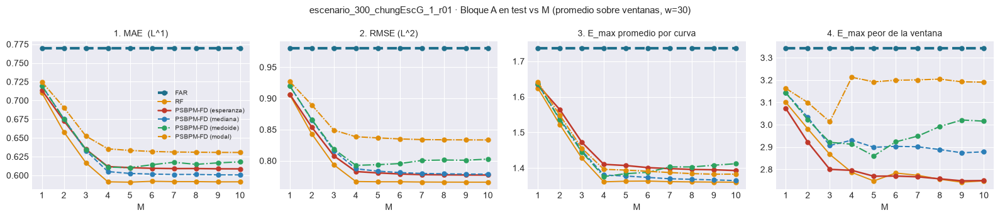

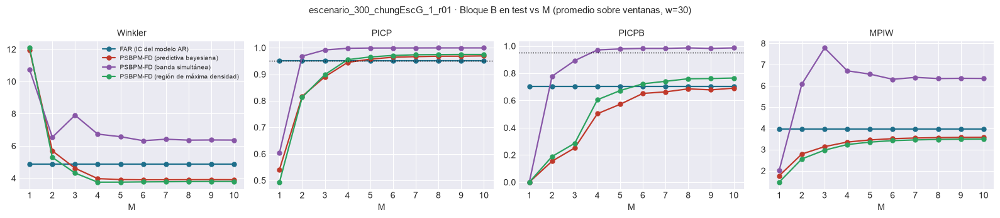

In [16]:
# Las métricas contra M: promedio en test sobre las ventanas, una línea por modelo / banda.
ESTILOS_BANDAS = {G_FAR: dict(color="#1f6f8b"), G_PSG: dict(color="#e08e0b"), G_PSB: dict(color="#c0392b"),
                  G_PSS: dict(color="#8856a7"), G_PSH: dict(color="#2ca25f")}

plot_metricas_vs_M(promedio_vs_M(resumen_A, "modelo"), METRICAS_A, ESTILOS_MODELOS_PREDICTORES,
                   f"{EXPERIMENT_BASE} · Bloque A en test vs M (promedio sobre ventanas, w={W_REF})",
                   save_path=PATH_BARRIDO / f"{PREFIJO + 6}_bloqueA_vs_M.png")
plt.show()
plot_metricas_vs_M(promedio_vs_M(resumen_B, "banda"),
                   [("Winkler", "winkler"), ("PICP", "picp"), ("PICPB", "picp_simultaneo"), ("MPIW", "mpiw")],
                   ESTILOS_BANDAS,
                   f"{EXPERIMENT_BASE} · Bloque B en test vs M (promedio sobre ventanas, w={W_REF})",
                   nominal=NIVEL, save_path=PATH_BARRIDO / f"{PREFIJO + 7}_bloqueB_vs_M.png")
plt.show()

### 8.1 Cada construcción del PSBPM-FD contra el FAR

Winkler medio en test menos el del FAR y % de ventanas ganadas cara a cara (`111_*`).

In [17]:
B_VS_FAR = bloqueB_contra_far(EST, PATH_BARRIDO)
display(B_VS_FAR.style.format(precision=4)
        .set_caption("Bloque B · construcciones del PSBPM-FD contra el FAR (test, w de referencia)"))

,M,banda,n_ventanas,winkler,winkler_FAR,dif_winkler_vs_FAR,pct_ventanas_gana_FAR
0,1,PSBPM-FD (banda simultánea),271,10.7352,4.8633,5.8719,0.0000
1,1,PSBPM-FD (predictiva bayesiana),271,11.9531,4.8633,7.0898,0.0000
2,1,PSBPM-FD (región de máxima densidad),271,12.0854,4.8633,7.2221,0.0000
3,2,PSBPM-FD (banda simultánea),271,6.5381,4.8633,1.6748,0.0000
4,2,PSBPM-FD (predictiva bayesiana),271,5.6930,4.8633,0.8297,0.1919
5,2,PSBPM-FD (región de máxima densidad),271,5.2861,4.8633,0.4228,0.2952
6,3,PSBPM-FD (banda simultánea),271,7.9066,4.8633,3.0433,0.0000
7,3,PSBPM-FD (predictiva bayesiana),271,4.6135,4.8633,-0.2498,0.6679
8,3,PSBPM-FD (región de máxima densidad),271,4.3141,4.8633,-0.5492,0.8413
9,4,PSBPM-FD (banda simultánea),271,6.7314,4.8633,1.8681,0.0000


## 9. Intervalos de credibilidad: FAR contra PSBPM-FD, en la ventana de detalle

Tres figuras por $M$ (FAR contra equi-colas, HDR y simultánea) y la tabla de ancho y cobertura por origen, con la cobertura de curva completa como cuenta.

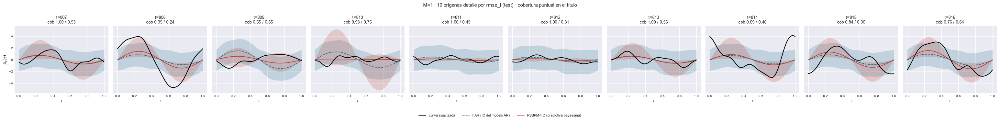

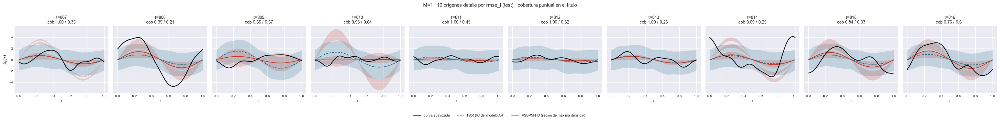

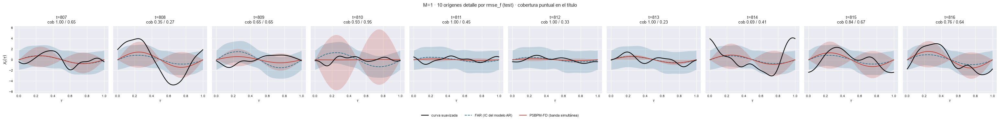

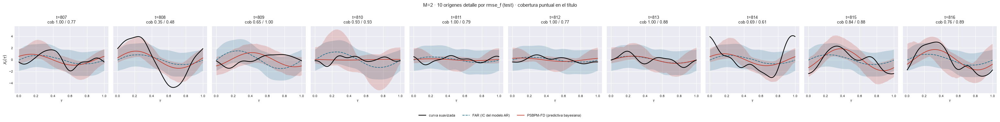

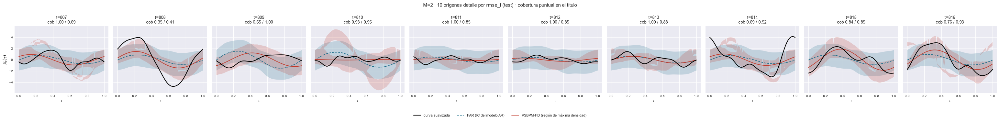

...

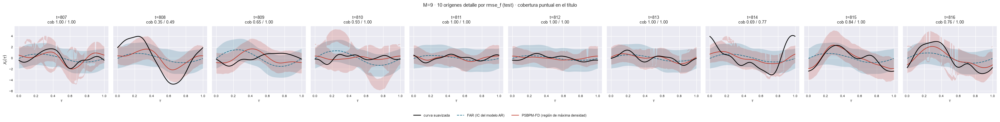

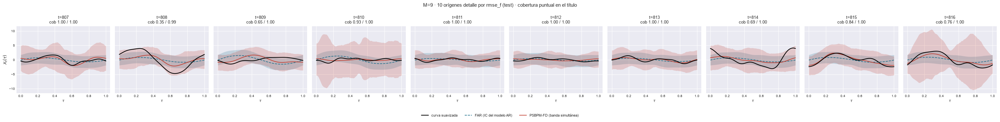

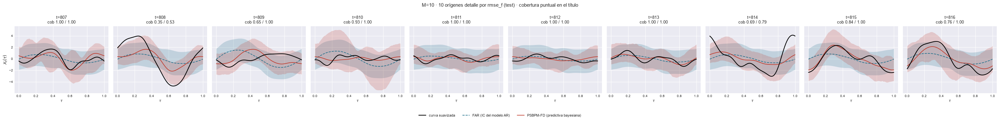

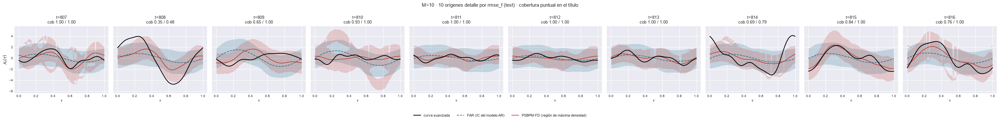

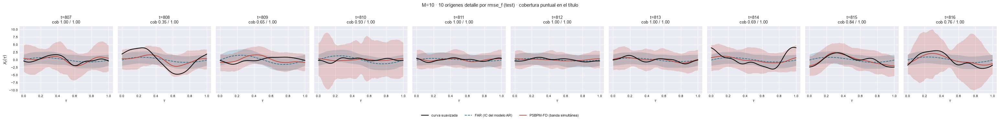

In [18]:
M_9 = M_OK if M_DETALLE is None else tuple(m for m in M_DETALLE if m in M_OK)
DETALLE = {"detalle": IDX_DET}
for M in M_9:
    for par, sufijo in ((BANDA_A_CONTRASTAR, ""), (("FAR", G_PSH), "_hdr"), (("FAR", G_PSS), "_simultanea")):
        plot_bandas_contraste(
            EST[M]["BANDAS"], DETALLE, X_obj_ev, grilla, t_orig, M, METRICA_SEL_IC, par, "detalle",
            EST[M]["paths"]["out_report"] / f"{PREFIJO + 9}_ic_contraste_detalle{sufijo}.png")
        plt.show()

In [19]:
# Ancho y cobertura por origen de cada banda en la ventana de detalle (79_ic_contraste_origenes.csv por M).
filas = []
for M in M_9:
    for i in IDX_DET:
        for nombre, ((L, U), _Xp) in EST[M]["BANDAS"].items():
            dentro = cobertura_tramos(X_obj_ev[i], L[i], U[i])
            filas.append({"M": M, "t": int(t_orig[i]), "banda": nombre,
                          "mpiw": float(ancho_tramos(L[i], U[i]).mean()),
                          "picp_puntual": float(dentro.mean()), "I_t_simultaneo": float(dentro.all())})
ic_df = pd.DataFrame(filas)
for M in M_9:
    ic_df[ic_df.M == M].drop(columns="M").to_csv(
        EST[M]["paths"]["out_report"] / f"{PREFIJO + 9}_ic_contraste_origenes.csv", index=False)
display(ic_df.groupby(["M", "banda"]).agg(mpiw=("mpiw", "mean"), picp_puntual=("picp_puntual", "mean"),
                                          curvas_cubiertas=("I_t_simultaneo", "sum"))
        .style.format({"mpiw": "{:.3f}", "picp_puntual": "{:.3f}", "curvas_cubiertas": "{:.0f}"})
        .set_caption(f"Ventana de detalle (t={T0_DET}..): curvas_cubiertas = cuántas de las {N_DETALLE} "
                     "quedan enteras dentro de la banda (descriptivo)"))
print("Lectura: si el MPIW del FAR es prácticamente el mismo en todos los orígenes, es porque su ancho NO")
print("depende del origen (su Sigma_eps es la misma para todo t); que el del PSBPM-FD cambie entre orígenes")
print("es la flexibilidad de una predictiva que depende del estado.")

Lectura: si el MPIW del FAR es prácticamente el mismo en todos los orígenes, es porque su ancho NO
depende del origen (su Sigma_eps es la misma para todo t); que el del PSBPM-FD cambie entre orígenes
es la flexibilidad de una predictiva que depende del estado.


## 10. Comportamientos predictivos contra lo observado

En la ventana de detalle, como cuentas: comportamiento en que cae lo observado, su probabilidad, si es el más probable, y cobertura, ancho y Winkler de la banda del comportamiento realizado, del más probable y de la marginal, contra $X_t^{(M)}$.

In [20]:
# validar_observado sobre TODO el bloque de prueba (las cifras del cuerpo) y, aparte, sobre la ventana de
# detalle (las cuentas de k de 10). La máscara de los comportamientos se restringe a cada subconjunto. Por
# subconjunto y objetivo, dos filas de resumen: todos los orígenes y sólo K >= 2 (donde el comportamiento
# realizado y el más probable se apartan de la marginal). Error en el origen de la curva típica (realizado =
# cota, más probable = pronóstico) y de las referencias puntuales: esperanza del PSBPM-FD, FAR y RF.
SUBCONJUNTOS = {"test": ~es_train, "detalle": MASK_DET}
partes, res = [], []
for M in M_OK:
    e = EST[M]
    C = cargar_comportamientos(e["paths"])
    assert C is not None and np.array_equal(C["t_orig"], t_orig), f"[M={M}] falta el §12 del _04."
    li_f, ls_f = e["BANDA_PSBP"]
    por_M = []
    for sub, mask in SUBCONJUNTOS.items():
        C["mascara"] = mask.copy()
        for objetivo, Y in (("curva_suavizada", X_obj_ev), ("representacion_fpca", e["X_proj"])):
            v = validar_observado(C, e["Y_obs"], Y, li_f, ls_f, grilla, PESOS_TAU,
                                  curvas_ref={"esperanza": e["X_PSBP"], "FAR": e["CURVAS"]["FAR"],
                                              "RF": e["CURVAS"]["RF"]})
            v.insert(0, "subconjunto", sub)
            v.insert(1, "objetivo", objetivo)
            v.insert(2, "t", t_orig[v["i"].to_numpy()])
            por_M.append(v)
            for grupo, g in (("todos", v), ("K>=2", v[v.K >= 2])):
                fila = {"M": M, "subconjunto": sub, "objetivo": objetivo, "origenes": grupo, "n": int(len(g))}
                if len(g):
                    fila.update({"K >= 2": int((g.K >= 2).sum()),
                                 "cae en el más probable": float(g.acierto.mean()),
                                 "p_obs media": float(g.p_obs.mean()), "p_esperada media": float(g.p_esperada.mean()),
                                 **{f"{m}_{k}": float(g[f"{m}_{k}"].mean()) for m in ("mae", "rmse")
                                    for k in ("real", "mp", "esperanza", "FAR", "RF")},
                                 "mp gana a FAR": float((g.mae_mp < g.mae_FAR).mean()),
                                 "mp gana a RF": float((g.mae_mp < g.mae_RF).mean()),
                                 "mp gana a esperanza": float((g.mae_mp < g.mae_esperanza).mean()),
                                 "curva entera en banda real": float(g.picpb_real.mean()),
                                 "curva entera en banda mp": float(g.picpb_mp.mean()),
                                 "curva entera en banda marginal": float(g.picpb_marg.mean()),
                                 "mpiw_real": float(g.mpiw_real.mean()), "mpiw_mp": float(g.mpiw_mp.mean()),
                                 "mpiw_marg": float(g.mpiw_marg.mean()), "winkler_real": float(g.winkler_real.mean()),
                                 "winkler_mp": float(g.winkler_mp.mean()), "winkler_marg": float(g.winkler_marg.mean())})
                res.append(fila)
    pd.concat(por_M, ignore_index=True).to_csv(e["paths"]["out_report"] / "82_validacion_comportamientos.csv",
                                              index=False)
    pd.DataFrame([r for r in res if r["M"] == M]).to_csv(e["paths"]["out_report"] / "83_validacion_resumen.csv",
                                                         index=False)
VAL_COMP = pd.DataFrame(res).assign(t0_detalle=T0_DET)
VAL_COMP.to_csv(PATH_BARRIDO / "105_validacion_comportamientos_por_M.csv", index=False)
COLS = ["n", "K >= 2", "cae en el más probable", "mae_mp", "mae_real", "mae_esperanza", "mae_FAR", "mae_RF",
        "mp gana a FAR", "mp gana a RF", "mp gana a esperanza", "curva entera en banda marginal"]
for sub, nota in (("test", "fracciones sobre todo el bloque de prueba"),
                  ("detalle", f"ventana de detalle t={T0_DET}..{T0_DET + N_DETALLE - 1}: fracciones de {N_DETALLE} orígenes")):
    display(VAL_COMP[(VAL_COMP.subconjunto == sub) & (VAL_COMP.objetivo == "curva_suavizada")]
            .set_index(["M", "origenes"])[COLS].style.format(precision=3)
            .set_caption(f"Comportamientos contra lo observado · {nota} · objetivo = curva suavizada"))


,origenes,K >= 2,cae en el más probable,p_obs media,p_esperada media,mae_real,mae_mp,mae_esperanza,mae_FAR,mae_RF,rmse_real,rmse_mp,rmse_esperanza,rmse_FAR,rmse_RF,mp gana a FAR,mp gana a RF,mp gana a esperanza,curva entera en banda real,curva entera en banda mp,curva entera en banda marginal,mpiw_real,mpiw_mp,mpiw_marg,winkler_real,winkler_mp,winkler_marg
M,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,10,6,8,0.806,0.838,0.248,0.460,0.371,0.594,0.363,0.275,0.511,0.412,0.662,0.403,7,3,4,9,7,10,1.002,0.866,1.904,1.204,8.379,1.930
2,10,6,7,0.705,0.751,0.459,0.708,0.643,0.925,0.593,0.509,0.787,0.715,1.029,0.658,8,4,4,8,6,8,2.117,1.958,3.104,2.409,12.335,4.780
3,10,6,7,0.741,0.784,0.517,0.763,0.677,1.033,0.624,0.589,0.859,0.765,1.161,0.707,9,4,4,7,6,8,2.587,2.439,3.528,2.980,10.824,5.031
4,10,6,7,0.742,0.784,0.580,0.809,0.727,1.081,0.698,0.668,0.919,0.829,1.230,0.807,9,4,4,7,6,8,2.909,2.780,3.779,3.950,10.202,5.490
5,10,6,7,0.742,0.784,0.598,0.829,0.745,1.092,0.722,0.703,0.941,0.852,1.247,0.843,9,4,4,7,6,8,3.026,2.902,3.873,4.243,9.905,5.530
6,10,6,7,0.742,0.784,0.606,0.836,0.755,1.093,0.735,0.710,0.948,0.859,1.252,0.857,9,4,4,8,6,8,3.096,2.976,3.925,4.219,9.639,5.524
7,10,6,7,0.741,0.784,0.614,0.844,0.760,1.097,0.742,0.719,0.956,0.867,1.258,0.867,9,4,5,8,6,8,3.130,3.011,3.954,4.273,9.543,5.565
8,10,6,7,0.741,0.784,0.619,0.847,0.764,1.099,0.745,0.723,0.960,0.872,1.262,0.870,9,4,5,7,6,8,3.149,3.034,3.970,4.274,9.469,5.586
9,10,6,7,0.742,0.784,0.625,0.848,0.766,1.098,0.747,0.726,0.962,0.874,1.263,0.873,9,4,5,7,6,8,3.160,3.044,3.979,4.286,9.583,5.578


,origenes,K >= 2,cae en el más probable,p_obs media,p_esperada media,mae_real,mae_mp,mae_esperanza,mae_FAR,mae_RF,rmse_real,rmse_mp,rmse_esperanza,rmse_FAR,rmse_RF,mp gana a FAR,mp gana a RF,mp gana a esperanza,curva entera en banda real,curva entera en banda mp,curva entera en banda marginal,mpiw_real,mpiw_mp,mpiw_marg,winkler_real,winkler_mp,winkler_marg
M,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,10,6,8,0.806,0.838,0.847,0.976,0.929,1.100,0.932,0.983,1.122,1.066,1.264,1.072,7,4,6,0,0,0,1.002,0.866,1.904,20.520,26.275,15.664
2,10,6,7,0.705,0.751,0.719,0.932,0.858,1.100,0.811,0.838,1.061,0.987,1.264,0.948,8,4,4,1,1,1,2.117,1.958,3.104,6.791,15.589,6.674
3,10,6,7,0.741,0.784,0.682,0.892,0.807,1.100,0.761,0.788,1.011,0.923,1.264,0.884,9,4,4,2,2,4,2.587,2.439,3.528,5.144,12.409,5.986
4,10,6,7,0.742,0.784,0.625,0.845,0.762,1.100,0.742,0.728,0.962,0.876,1.264,0.866,9,4,5,7,6,7,2.909,2.780,3.779,4.322,10.566,5.633
5,10,6,7,0.742,0.784,0.627,0.847,0.766,1.100,0.747,0.728,0.965,0.877,1.264,0.873,9,4,5,8,6,8,3.026,2.902,3.873,4.279,10.137,5.588
6,10,6,7,0.742,0.784,0.628,0.849,0.768,1.100,0.751,0.729,0.965,0.877,1.264,0.876,9,4,5,8,6,8,3.096,2.976,3.925,4.265,9.869,5.552
7,10,6,7,0.741,0.784,0.626,0.848,0.768,1.100,0.752,0.728,0.964,0.877,1.264,0.877,9,4,5,8,6,8,3.130,3.011,3.954,4.271,9.725,5.561
8,10,6,7,0.741,0.784,0.625,0.848,0.768,1.100,0.750,0.727,0.963,0.875,1.264,0.874,9,4,5,8,6,8,3.149,3.034,3.970,4.276,9.646,5.574
9,10,6,7,0.742,0.784,0.626,0.849,0.768,1.100,0.750,0.727,0.963,0.876,1.264,0.874,9,4,5,8,6,8,3.160,3.044,3.979,4.284,9.640,5.561
